In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import precision_score, roc_auc_score



print("Current working directory:", os.getcwd())
files = glob.glob("*")
print("Files:", [f for f in files if f.endswith('.csv') or f.endswith('.xlsx') or f.endswith('.txt')])

Current working directory: /content
Files: ['09_prestataires.csv', '01_residences.csv', '03_logements.csv', '10_ref_seuils_dpe.csv', 'predictions_defi1_2026.csv', '04_equipements.csv', '02_batiments.csv', '10_ref_familles_equipements.csv', '08_plan_investissement.csv', '10_ref_motifs_demandes.csv', '05_demandes_locataires.csv', '07_commandes.csv', '06_interventions.csv']


In [ ]:
for f in sorted(glob.glob("*.csv")):
    df = pd.read_csv(f)
    print(f"=== {f} (shape: {df.shape}) ===")
    print(df.head(2))
    print(df.columns.tolist())
    print()

=== 01_residences.csv (shape: (8, 16)) ===
  residence_id          nom                                      localisation  \
0        RES-A  Résidence A  Métropole toulousaine (31) - zone climatique H2c   
1        RES-B  Résidence B  Métropole toulousaine (31) - zone climatique H2c   

   annee_construction  nb_batiments  nb_logements  \
0                1985             6           160   
1                1992             4            60   

   surface_habitable_totale_m2 ascenseur energie_chauffage type_chauffage  \
0                         9072       Non               Gaz     Individuel   
1                         3529       Oui       Électricité     Individuel   

                                generateur_chauffage  \
0  Chaudière gaz individuelle (mixte chauffage + ...   
1               Radiateurs électriques (convecteurs)   

                 production_ecs                   ventilation  \
0         Gaz (chaudière mixte)  VMC simple flux autoréglable   
1  Ballon électrique i

In [ ]:
df_equip = pd.read_csv("04_equipements.csv")
print("Total equipements:", len(df_equip))
print("dans_perimetre_prediction value counts:")
print(df_equip['dans_perimetre_prediction'].value_counts())

df_interv = pd.read_csv("06_interventions.csv")
print("\nInterventions date range:")
print("Min date:", df_interv['date_intervention'].min(), "Max date:", df_interv['date_intervention'].max())
print("Type intervention counts:")
print(df_interv['type_intervention'].value_counts())
print("\nGravite counts:")
print(df_interv['gravite'].value_counts(dropna=False))
print("\nEquipements in perimetre in interv:")
perim_ids = set(df_equip[df_equip['dans_perimetre_prediction'] == 'Oui']['equipement_id'])
print("Total perim_ids:", len(perim_ids))
print("Interventions on perim equipements:", df_interv['equipement_id'].isin(perim_ids).sum())

Total equipements: 4217
dans_perimetre_prediction value counts:
dans_perimetre_prediction
Non    2932
Oui    1285
Name: count, dtype: int64

Interventions date range:
Min date: 2018-01-01 09:07 Max date: 2025-12-31 17:10
Type intervention counts:
type_intervention
Entretien préventif    19809
Dépannage               9955
Remplacement             866
Name: count, dtype: int64

Gravite counts:
gravite
NaN                       20675
Fonctionnement dégradé     5241
Gêne mineure               3350
Arrêt total                1364
Name: count, dtype: int64

Equipements in perimetre in interv:
Total perim_ids: 1285
Interventions on perim equipements: 10067


In [ ]:
print("Familles dans le périmètre :")
print(df_equip[df_equip['dans_perimetre_prediction'] == 'Oui']['famille'].value_counts())
print("\nFamilles hors périmètre :")
print(df_equip[df_equip['dans_perimetre_prediction'] == 'Non']['famille'].value_counts())

Familles dans le périmètre :
famille
chaudiere_gaz_individuelle    400
convecteurs_electriques       230
ballon_ecs_electrique         230
panneaux_rayonnants           140
ballon_thermodynamique        140
pompe_a_chaleur               100
caisson_vmc                    23
ascenseur                      15
chaufferie_collective           5
production_ecs_solaire          2
Name: count, dtype: int64

Familles hors périmètre :
famille
robinetterie_sanitaires    1100
volets_roulants            1100
bouches_vmc                 700
porte_hall_interphonie       32
Name: count, dtype: int64


In [ ]:
df_interv['date_dt'] = pd.to_datetime(df_interv['date_intervention'])
interv_perim = df_interv[df_interv['equipement_id'].isin(perim_ids)].copy()

# Look at 2025-01-01 to 2025-09-30
mask_val_target = (
    (interv_perim['date_dt'] >= '2025-01-01') &
    (interv_perim['date_dt'] <= '2025-09-30 23:59:59') &
    (interv_perim['gravite'] == 'Arrêt total')
)

target_val = interv_perim[mask_val_target]
print("Nombre total d'interventions Arrêt total en janv-sept 2025 sur le périmètre:", len(target_val))
print("Nombre d'équipements distincts touchés:", target_val['equipement_id'].nunique())
print("Répartition par famille :")
eq_merged = target_val.merge(df_equip[['equipement_id', 'famille']], on='equipement_id')
print(eq_merged['famille'].value_counts())

Nombre total d'interventions Arrêt total en janv-sept 2025 sur le périmètre: 86
Nombre d'équipements distincts touchés: 76
Répartition par famille :
famille
chaudiere_gaz_individuelle    32
pompe_a_chaleur               19
convecteurs_electriques       10
ballon_thermodynamique        10
ballon_ecs_electrique         10
chaufferie_collective          2
caisson_vmc                    2
ascenseur                      1
Name: count, dtype: int64


In [ ]:
interv_perim['year'] = interv_perim['date_dt'].dt.year
interv_perim['month'] = interv_perim['date_dt'].dt.month

print("Arrêt total par an sur les équipements du périmètre:")
print(interv_perim[interv_perim['gravite'] == 'Arrêt total'].groupby('year')['equipement_id'].agg(['count', 'nunique']))

print("\nArrêt total entre janv et sept par an:")
print(interv_perim[(interv_perim['gravite'] == 'Arrêt total') & (interv_perim['month'] <= 9)].groupby('year')['equipement_id'].agg(['count', 'nunique']))

Arrêt total par an sur les équipements du périmètre:
      count  nunique
year                
2018     60       51
2019     92       76
2020     88       75
2021     83       70
2022     98       80
2023     87       78
2024    104       87
2025    122      104

Arrêt total entre janv et sept par an:
      count  nunique
year                
2018     39       34
2019     69       57
2020     64       54
2021     64       52
2022     76       60
2023     64       59
2024     75       64
2025     86       76


In [ ]:
print(df_equip[df_equip['nb_remplacements_2018_2025'] > 0][['equipement_id', 'date_pose', 'date_pose_precedente', 'nb_remplacements_2018_2025', 'dans_perimetre_prediction']].head(10))
print("\nNumber of replacements in perimeter:")
print(df_equip[df_equip['dans_perimetre_prediction'] == 'Oui']['nb_remplacements_2018_2025'].value_counts())

   equipement_id   date_pose date_pose_precedente  nb_remplacements_2018_2025  \
2      EQP-00003  2024-05-29           1985-06-01                           1   
19     EQP-00020  2021-06-14           1987-08-31                           1   
29     EQP-00030  2023-12-01           1985-06-01                           1   
30     EQP-00031  2021-09-08           2005-09-19                           1   
36     EQP-00037  2024-01-23           2016-03-24                           1   
41     EQP-00042  2021-10-15           1985-06-01                           1   
42     EQP-00043  2024-06-27           1985-06-01                           1   
44     EQP-00045  2021-08-01           2016-03-07                           1   
48     EQP-00049  2022-04-29           2016-03-22                           1   
51     EQP-00052  2021-12-10           1985-06-01                           1   

   dans_perimetre_prediction  
2                        Non  
19                       Non  
29             

In [ ]:
print("Equipements in perimetre with date_pose in 2025:")
perim_df = df_equip[df_equip['dans_perimetre_prediction'] == 'Oui']
print(perim_df[perim_df['date_pose'] >= '2025-01-01'][['equipement_id', 'date_pose', 'date_pose_precedente', 'nb_remplacements_2018_2025']])

Equipements in perimetre with date_pose in 2025:
     equipement_id   date_pose date_pose_precedente  \
52       EQP-00053  2025-11-12           2016-03-05   
184      EQP-00185  2025-03-25           2016-02-05   
308      EQP-00309  2025-04-02           2016-07-14   
384      EQP-00385  2025-02-25           2016-03-07   
612      EQP-00613  2025-12-17           2016-11-28   
...            ...         ...                  ...   
4084     EQP-04085  2025-02-06           2009-06-01   
4108     EQP-04109  2025-02-25           2009-06-01   
4151     EQP-04152  2025-05-17           2003-04-10   
4166     EQP-04167  2025-02-11           1994-05-12   
4198     EQP-04199  2025-05-22           1995-07-13   

      nb_remplacements_2018_2025  
52                             1  
184                            1  
308                            1  
384                            1  
612                            1  
...                          ...  
4084                           1  
4108      

In [ ]:
# Let's inspect all replacements in df_interv for any equipement
# For each equipment, what are its replacements in 06_interventions?
rempl = df_interv[df_interv['type_intervention'] == 'Remplacement'].sort_values('date_dt')
print("Remplacements on perimetre:", rempl[rempl['equipement_id'].isin(perim_ids)]['equipement_id'].nunique())
print("Total replacements on perimetre:", len(rempl[rempl['equipement_id'].isin(perim_ids)]))

Remplacements on perimetre: 459
Total replacements on perimetre: 471


In [ ]:
# Check equipment with 2 replacements
eq2 = df_equip[(df_equip['dans_perimetre_prediction'] == 'Oui') & (df_equip['nb_remplacements_2018_2025'] == 2)]
print("Equipements with 2 replacements:", eq2['equipement_id'].tolist()[:5])

sample_id = eq2.iloc[0]['equipement_id']
print(f"\nEquipment {sample_id} info:")
print(eq2.iloc[0])
print(f"\nInterventions for {sample_id}:")
print(df_interv[df_interv['equipement_id'] == sample_id][['date_intervention', 'type_intervention', 'symptome', 'gravite', 'resultat', 'commentaire_technicien']])

Equipements with 2 replacements: ['EQP-02377', 'EQP-02432', 'EQP-03170', 'EQP-03346', 'EQP-03458']

Equipment EQP-02377 info:
equipement_id                                                 EQP-02377
famille                                          ballon_thermodynamique
libelle_famille                                  Ballon thermodynamique
niveau_rattachement                                            Logement
residence_id                                                      RES-E
batiment_id                                                      BAT-E3
logement_id                                                  LGT-E3-022
date_pose                                                    2025-05-08
origine_date_pose             Remplacement tracé dans les interventions
date_pose_precedente                                         2021-01-04
nb_remplacements_2018_2025                                            2
duree_vie_reference_ans                                              14
sous_contr

In [ ]:
def charger_donnees():
    df_res = pd.read_csv("01_residences.csv")
    df_bat = pd.read_csv("02_batiments.csv")
    df_lgt = pd.read_csv("03_logements.csv")
    df_eqp = pd.read_csv("04_equipements.csv")
    df_int = pd.read_csv("06_interventions.csv")
    df_dem = pd.read_csv("05_demandes_locataires.csv")

    df_int["date_dt"] = pd.to_datetime(df_int["date_intervention"])
    df_dem["date_dt"] = pd.to_datetime(df_dem["date_creation"])
    return df_res, df_bat, df_lgt, df_eqp, df_int, df_dem


def extraire_features(
    date_pivot_str, df_eqp, df_int, df_dem, df_lgt, df_res
):
    pivot = pd.to_datetime(date_pivot_str)
    perim = df_eqp[df_eqp["dans_perimetre_prediction"] == "Oui"].copy()

    # 1. Neutralisation du Data Leakage sur la date de pose
    # On reconstitue la date de pose active à la date pivot
    rempl_post = df_int[
        (df_int["type_intervention"] == "Remplacement")
        & (df_int["date_dt"] > pivot)
    ]
    eqp_remplaces_apres_pivot = set(rempl_post["equipement_id"])

    date_pose_active = []
    for _, row in perim.iterrows():
        eq_id = row["equipement_id"]
        dp = pd.to_datetime(row["date_pose"])
        if eq_id in eqp_remplaces_apres_pivot:
            if pd.notna(row["date_pose_precedente"]):
                date_pose_active.append(
                    pd.to_datetime(row["date_pose_precedente"])
                )
            else:
                date_pose_active.append(dp)
        else:
            date_pose_active.append(dp)
    perim["date_pose_active"] = date_pose_active

    # Calcul de l'âge et de l'usure
    perim["age_ans"] = (pivot - perim["date_pose_active"]).dt.days / 365.25
    perim["ratio_usure"] = (
        perim["age_ans"] / perim["duree_vie_reference_ans"]
    ).clip(0, 3)

    # 2. Historique GMAO strictement antérieur à la date pivot
    int_hist = df_int[
        (df_int["equipement_id"].isin(perim["equipement_id"]))
        & (df_int["date_dt"] <= pivot)
    ].copy()

    # Découpage temporel
    m12 = pivot - pd.DateOffset(months=12)
    m24 = pivot - pd.DateOffset(months=24)

    # Variables d'interventions
    dep_tot = (
        int_hist[int_hist["type_intervention"] == "Dépannage"]
        .groupby("equipement_id")
        .size()
        .rename("dep_total")
    )
    dep_12m = (
        int_hist[
            (int_hist["type_intervention"] == "Dépannage")
            & (int_hist["date_dt"] >= m12)
        ]
        .groupby("equipement_id")
        .size()
        .rename("dep_12m")
    )
    arret_tot = (
        int_hist[int_hist["gravite"] == "Arrêt total"]
        .groupby("equipement_id")
        .size()
        .rename("arret_total_passe")
    )
    degrade_tot = (
        int_hist[int_hist["gravite"] == "Fonctionnement dégradé"]
        .groupby("equipement_id")
        .size()
        .rename("degrade_passe")
    )

    # Visites préventives manquées ou signalées avec anomalie
    prev_anom = (
        int_hist[
            (int_hist["type_intervention"] == "Entretien préventif")
            & (int_hist["resultat"].str.contains("Anomalie", na=False))
        ]
        .groupby("equipement_id")
        .size()
        .rename("prev_anomalies")
    )
    prev_manq = (
        int_hist[
            (int_hist["type_intervention"] == "Entretien préventif")
            & (int_hist["resultat"].str.contains("non réalisée|absent", na=False))
        ]
        .groupby("equipement_id")
        .size()
        .rename("prev_manquees")
    )

    # Dernière visite préventive
    derniere_prev = (
        int_hist[int_hist["type_intervention"] == "Entretien préventif"]
        .groupby("equipement_id")["date_dt"]
        .max()
    )
    jours_depuis_prev = (
        (pivot - derniere_prev).dt.days.rename("jours_depuis_derniere_prev")
    )

    # Signaux faibles textuels
    mots_cles = (
        r"fuite|bruit|sifflement|pression|carte|corrosion|usure|vétuste|anomalie"
    )
    nlp_alertes = (
        int_hist[
            int_hist["commentaire_technicien"].str.contains(
                mots_cles, case=False, na=False
            )
        ]
        .groupby("equipement_id")
        .size()
        .rename("signaux_nlp_commentaires")
    )

    # Assemblage
    feats = perim.copy()
    for s in [
        dep_tot,
        dep_12m,
        arret_tot,
        degrade_tot,
        prev_anom,
        prev_manq,
        jours_depuis_prev,
        nlp_alertes,
    ]:
        feats = feats.merge(s, on="equipement_id", how="left")

    cols_a_zero = [
        "dep_total",
        "dep_12m",
        "arret_total_passe",
        "degrade_passe",
        "prev_anomalies",
        "prev_manquees",
        "signaux_nlp_commentaires",
    ]
    feats[cols_a_zero] = feats[cols_a_zero].fillna(0)
    feats["jours_depuis_derniere_prev"] = feats[
        "jours_depuis_derniere_prev"
    ].fillna(730)

    # Données bâtiment & DPE
    feats = feats.merge(
        df_lgt[["logement_id", "dpe_conso_ep_kwh_m2_an", "dpe_ges_kgco2_m2_an"]],
        on="logement_id",
        how="left",
    )
    feats["dpe_conso_ep_kwh_m2_an"] = feats["dpe_conso_ep_kwh_m2_an"].fillna(
        feats["dpe_conso_ep_kwh_m2_an"].median()
    )

    # Encodage catégoriel
    feats["famille"] = feats["famille"].astype("category")
    feats["prestataire_id"] = feats["prestataire_id"].astype("category")

    colonnes_x = [
        "age_ans",
        "ratio_usure",
        "dep_total",
        "dep_12m",
        "arret_total_passe",
        "degrade_passe",
        "prev_anomalies",
        "prev_manquees",
        "jours_depuis_derniere_prev",
        "signaux_nlp_commentaires",
        "dpe_conso_ep_kwh_m2_an",
        "famille",
        "prestataire_id",
    ]
    return feats, colonnes_x


def entrainer_et_predire():
    df_res, df_bat, df_lgt, df_eqp, df_int, df_dem = charger_donnees()

    # --- ÉTAPE 1 : BACKTESTING SUR 2024-2025 ---
    df_train, cols_x = extraire_features(
        "2024-12-31", df_eqp, df_int, df_dem, df_lgt, df_res
    )

    # Cible réelle : au moins 1 Arrêt total entre 01/01/2025 et 30/09/2025
    cible_val = df_int[
        (df_int["date_dt"] >= "2025-01-01")
        & (df_int["date_dt"] <= "2025-09-30 23:59:59")
        & (df_int["gravite"] == "Arrêt total")
    ]
    ids_en_panne_2025 = set(cible_val["equipement_id"])
    y_val = df_train["equipement_id"].isin(ids_en_panne_2025).astype(int)

    # Évaluation baseline « âge seul »
    auc_base = roc_auc_score(y_val, df_train["ratio_usure"])
    top10_n = int(0.10 * len(df_train))
    top10_base_idx = np.argsort(df_train["ratio_usure"].values)[::-1][:top10_n]
    prec_base = y_val.iloc[top10_base_idx].mean()

    # Modèle ML
    model = LGBMClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=4,
        scale_pos_weight=15,
        random_state=42,
    )
    model.fit(df_train[cols_x], y_val)

    scores_val = model.predict_proba(df_train[cols_x])[:, 1]
    auc_ml = roc_auc_score(y_val, scores_val)
    top10_ml_idx = np.argsort(scores_val)[::-1][:top10_n]
    prec_ml = y_val.iloc[top10_ml_idx].mean()

    print(
        f"Validation (2025) - Baseline Âge : AUC = {auc_base:.3f} | Précision @ Top 10% = {prec_base * 100:.1f} %"
    )
    print(
        f"Validation (2025) - Modèle BâtIA : AUC = {auc_ml:.3f} | Précision @ Top 10% = {prec_ml * 100:.1f} %"
    )

    # --- ÉTAPE 2 : INFÉRENCE POUR LE DÉFI 1 (2026) ---
    df_infer, _ = extraire_features(
        "2025-12-31", df_eqp, df_int, df_dem, df_lgt, df_res
    )
    scores_2026 = model.predict_proba(df_infer[cols_x])[:, 1]

    # Génération du livrable CSV officiel
    livrable = pd.DataFrame(
        {
            "equipement_id": df_infer["equipement_id"],
            "score_risque": np.round(scores_2026, 4),
        }
    ).sort_values("score_risque", ascending=False)

    livrable.to_csv("predictions_defi1_2026.csv", index=False)
    print("Fichier 'predictions_defi1_2026.csv' généré avec succès.")
    return livrable


if __name__ == "__main__":
    entrainer_et_predire()

[LightGBM] [Info] Number of positive: 76, number of negative: 1209
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000406 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 947
[LightGBM] [Info] Number of data points in the train set: 1285, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.059144 -> initscore=-2.766816
[LightGBM] [Info] Start training from score -2.766816
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, bes

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import roc_auc_score

# Load tables
df_res = pd.read_csv("01_residences.csv")
df_bat = pd.read_csv("02_batiments.csv")
df_lgt = pd.read_csv("03_logements.csv")
df_eqp = pd.read_csv("04_equipements.csv")
df_int = pd.read_csv("06_interventions.csv")
df_dem = pd.read_csv("05_demandes_locataires.csv")

df_int['date_dt'] = pd.to_datetime(df_int['date_intervention'])
df_dem['date_dt'] = pd.to_datetime(df_dem['date_creation'])

# Let's inspect all columns of df_dem and df_int to extract more features
print("Demandes columns:", df_dem.columns.tolist())
print("Interventions columns:", df_int.columns.tolist())

Demandes columns: ['demande_id', 'date_creation', 'date_cloture', 'logement_id', 'batiment_id', 'residence_id', 'parties', 'canal', 'motif', 'objet', 'texte_demande', 'priorite', 'nb_echanges', 'demande_reouverte', 'delai_resolution_h', 'date_dt']
Interventions columns: ['intervention_id', 'date_intervention', 'residence_id', 'batiment_id', 'logement_id', 'equipement_id', 'type_intervention', 'code_metier', 'prestataire_id', 'symptome', 'gravite', 'resultat', 'commentaire_technicien', 'demande_id_liee', 'date_dt']


In [ ]:
# Let's inspect how replacements are recorded in df_int
perim_eqs = df_eqp[df_eqp['dans_perimetre_prediction'] == 'Oui']
remplacements = df_int[(df_int['type_intervention'] == 'Remplacement') & (df_int['equipement_id'].isin(perim_eqs['equipement_id']))].sort_values('date_dt')
print("Total remplacements for perim eqs in df_int:", len(remplacements))
print(remplacements[['equipement_id', 'date_dt', 'resultat', 'commentaire_technicien']].head(10))

Total remplacements for perim eqs in df_int: 471
     equipement_id             date_dt             resultat  \
83       EQP-00792 2018-01-11 08:42:00  Équipement remplacé   
308      EQP-03102 2018-01-31 13:06:00  Équipement remplacé   
322      EQP-00786 2018-02-01 17:19:00  Équipement remplacé   
415      EQP-03614 2018-02-11 08:04:00  Équipement remplacé   
2170     EQP-03710 2018-04-21 08:58:00  Équipement remplacé   
2350     EQP-02665 2018-04-26 15:18:00  Équipement remplacé   
2514     EQP-04049 2018-05-02 10:38:00  Équipement remplacé   
2528     EQP-03198 2018-05-02 14:43:00  Équipement remplacé   
2969     EQP-03321 2018-05-25 13:27:00  Équipement remplacé   
2977     EQP-03005 2018-05-28 12:49:00  Équipement remplacé   

                             commentaire_technicien  
83    Pose d'un équipement neuf, mise en service OK  
308   Pose d'un équipement neuf, mise en service OK  
322   Pose d'un équipement neuf, mise en service OK  
415   Pose d'un équipement neuf, mise en 

In [ ]:
# Let's check consistency between df_eqp['date_pose'] and remplacements in df_int
# For an equipment with replacements:
rempl_by_eq = df_int[(df_int['type_intervention'] == 'Remplacement')].groupby('equipement_id')['date_dt'].apply(list).to_dict()

diffs = 0
for idx, row in perim_eqs.iterrows():
    eq = row['equipement_id']
    dp = row['date_pose']
    if eq in rempl_by_eq:
        last_rempl_date = str(rempl_by_eq[eq][-1].date())
        if last_rempl_date != str(dp)[:10]:
            diffs += 1
print(f"Diffs between last replacement in interventions and date_pose in df_eqp: {diffs}")

Diffs between last replacement in interventions and date_pose in df_eqp: 0


In [ ]:
# Let's inspect equipment with 2 replacements
eq_2rempl = df_eqp[(df_eqp['dans_perimetre_prediction'] == 'Oui') & (df_eqp['nb_remplacements_2018_2025'] == 2)]
for idx, row in eq_2rempl.iterrows():
    eq = row['equipement_id']
    print(eq, "date_pose:", row['date_pose'], "date_pose_precedente:", row['date_pose_precedente'], "rempl_dates:", [str(d.date()) for d in rempl_by_eq[eq]])

EQP-02377 date_pose: 2025-05-08 date_pose_precedente: 2021-01-04 rempl_dates: ['2021-01-04', '2025-05-08']
EQP-02432 date_pose: 2025-12-30 date_pose_precedente: 2019-06-10 rempl_dates: ['2019-06-10', '2025-12-30']
EQP-03170 date_pose: 2024-02-26 date_pose_precedente: 2018-08-02 rempl_dates: ['2018-08-02', '2024-02-26']
EQP-03346 date_pose: 2024-09-14 date_pose_precedente: 2019-06-09 rempl_dates: ['2019-06-09', '2024-09-14']
EQP-03458 date_pose: 2023-05-01 date_pose_precedente: 2018-10-26 rempl_dates: ['2018-10-26', '2023-05-01']
EQP-03501 date_pose: 2023-12-25 date_pose_precedente: 2018-12-10 rempl_dates: ['2018-12-10', '2023-12-25']
EQP-03542 date_pose: 2024-08-09 date_pose_precedente: 2020-04-27 rempl_dates: ['2020-04-27', '2024-08-09']
EQP-03614 date_pose: 2025-09-21 date_pose_precedente: 2018-02-11 rempl_dates: ['2018-02-11', '2025-09-21']
EQP-03698 date_pose: 2025-03-24 date_pose_precedente: 2019-11-25 rempl_dates: ['2019-11-25', '2025-03-24']
EQP-03766 date_pose: 2024-06-07 date_

In [ ]:
# Let's inspect rows with nb_remplacements > 0 and check their date_pose_precedente
print(df_equip[df_equip['nb_remplacements_2018_2025'] == 1][['equipement_id', 'date_pose', 'date_pose_precedente', 'origine_date_pose']].head(10))

   equipement_id   date_pose date_pose_precedente  \
2      EQP-00003  2024-05-29           1985-06-01   
19     EQP-00020  2021-06-14           1987-08-31   
29     EQP-00030  2023-12-01           1985-06-01   
30     EQP-00031  2021-09-08           2005-09-19   
36     EQP-00037  2024-01-23           2016-03-24   
41     EQP-00042  2021-10-15           1985-06-01   
42     EQP-00043  2024-06-27           1985-06-01   
44     EQP-00045  2021-08-01           2016-03-07   
48     EQP-00049  2022-04-29           2016-03-22   
51     EQP-00052  2021-12-10           1985-06-01   

                            origine_date_pose  
2   Remplacement tracé dans les interventions  
19  Remplacement tracé dans les interventions  
29  Remplacement tracé dans les interventions  
30  Remplacement tracé dans les interventions  
36  Remplacement tracé dans les interventions  
41  Remplacement tracé dans les interventions  
42  Remplacement tracé dans les interventions  
44  Remplacement tracé dans les 

In [ ]:
print(df_eqp[df_eqp['nb_remplacements_2018_2025'] == 1][['equipement_id', 'date_pose', 'date_pose_precedente', 'origine_date_pose']].head(10))

   equipement_id   date_pose date_pose_precedente  \
2      EQP-00003  2024-05-29           1985-06-01   
19     EQP-00020  2021-06-14           1987-08-31   
29     EQP-00030  2023-12-01           1985-06-01   
30     EQP-00031  2021-09-08           2005-09-19   
36     EQP-00037  2024-01-23           2016-03-24   
41     EQP-00042  2021-10-15           1985-06-01   
42     EQP-00043  2024-06-27           1985-06-01   
44     EQP-00045  2021-08-01           2016-03-07   
48     EQP-00049  2022-04-29           2016-03-22   
51     EQP-00052  2021-12-10           1985-06-01   

                            origine_date_pose  
2   Remplacement tracé dans les interventions  
19  Remplacement tracé dans les interventions  
29  Remplacement tracé dans les interventions  
30  Remplacement tracé dans les interventions  
36  Remplacement tracé dans les interventions  
41  Remplacement tracé dans les interventions  
42  Remplacement tracé dans les interventions  
44  Remplacement tracé dans les 

In [ ]:
print("Max date_pose in df_eqp:", df_eqp['date_pose'].max())
print("Min date_pose in df_eqp:", df_eqp['date_pose'].min())

Max date_pose in df_eqp: 2025-12-31
Min date_pose in df_eqp: 1968-06-01


In [ ]:
# Let's write a function to construct the dataset for any pivot year
def build_dataset_for_pivot(pivot_date_str, target_months=9):
    pivot = pd.to_datetime(pivot_date_str)
    perim = df_eqp[df_eqp['dans_perimetre_prediction'] == 'Oui'].copy()

    # 1. Active date pose at pivot date
    # Get all replacements in df_int up to pivot
    rempl_before_pivot = df_int[(df_int['type_intervention'] == 'Remplacement') & (df_int['date_dt'] <= pivot)]
    last_rempl_before = rempl_before_pivot.groupby('equipement_id')['date_dt'].max()

    rempl_after_pivot = df_int[(df_int['type_intervention'] == 'Remplacement') & (df_int['date_dt'] > pivot)]
    eqs_rempl_after = set(rempl_after_pivot['equipement_id'])

    active_dates = []
    for _, row in perim.iterrows():
        eq = row['equipement_id']
        if eq in last_rempl_before:
            active_dates.append(last_rempl_before[eq])
        elif eq in eqs_rempl_after:
            # Replaced only after pivot date
            if pd.notna(row['date_pose_precedente']):
                active_dates.append(pd.to_datetime(row['date_pose_precedente']))
            else:
                active_dates.append(pd.to_datetime(row['date_pose']))
        else:
            active_dates.append(pd.to_datetime(row['date_pose']))

    perim['date_pose_active'] = active_dates
    perim['age_ans'] = (pivot - perim['date_pose_active']).dt.total_seconds() / (365.25 * 86400)
    perim['ratio_usure'] = (perim['age_ans'] / perim['duree_vie_reference_ans']).clip(0, 3)

    # 2. Interventions strictly <= pivot
    int_hist = df_int[(df_int['equipement_id'].isin(perim['equipement_id'])) & (df_int['date_dt'] <= pivot)].copy()

    m6 = pivot - pd.DateOffset(months=6)
    m12 = pivot - pd.DateOffset(months=12)
    m24 = pivot - pd.DateOffset(months=24)
    m36 = pivot - pd.DateOffset(months=36)

    # Dépannages
    dep = int_hist[int_hist['type_intervention'] == 'Dépannage']
    dep_tot = dep.groupby('equipement_id').size().rename('dep_total')
    dep_6m = dep[dep['date_dt'] >= m6].groupby('equipement_id').size().rename('dep_6m')
    dep_12m = dep[dep['date_dt'] >= m12].groupby('equipement_id').size().rename('dep_12m')
    dep_24m = dep[dep['date_dt'] >= m24].groupby('equipement_id').size().rename('dep_24m')
    dep_36m = dep[dep['date_dt'] >= m36].groupby('equipement_id').size().rename('dep_36m')

    # Arrêts totaux
    arret_tot = int_hist[int_hist['gravite'] == 'Arrêt total'].groupby('equipement_id').size().rename('arret_total_passe')
    arret_12m = int_hist[(int_hist['gravite'] == 'Arrêt total') & (int_hist['date_dt'] >= m12)].groupby('equipement_id').size().rename('arret_12m')

    # Dégradé
    degrade_tot = int_hist[int_hist['gravite'] == 'Fonctionnement dégradé'].groupby('equipement_id').size().rename('degrade_passe')
    degrade_12m = int_hist[(int_hist['gravite'] == 'Fonctionnement dégradé') & (int_hist['date_dt'] >= m12)].groupby('equipement_id').size().rename('degrade_12m')

    # Entretien préventif
    prev = int_hist[int_hist['type_intervention'] == 'Entretien préventif']
    prev_tot = prev.groupby('equipement_id').size().rename('prev_tot')
    prev_anom = prev[prev['resultat'].str.contains('Anomalie', na=False)].groupby('equipement_id').size().rename('prev_anomalies')
    prev_anom_12m = prev[(prev['resultat'].str.contains('Anomalie', na=False)) & (prev['date_dt'] >= m12)].groupby('equipement_id').size().rename('prev_anom_12m')
    prev_manq = prev[prev['resultat'].str.contains('non réalisée|absent', na=False)].groupby('equipement_id').size().rename('prev_manquees')
    prev_manq_12m = prev[(prev['resultat'].str.contains('non réalisée|absent', na=False)) & (prev['date_dt'] >= m12)].groupby('equipement_id').size().rename('prev_manq_12m')

    derniere_prev = prev.groupby('equipement_id')['date_dt'].max()
    jours_depuis_prev = ((pivot - derniere_prev).dt.total_seconds() / 86400).rename('jours_depuis_derniere_prev')

    derniere_panne = dep.groupby('equipement_id')['date_dt'].max()
    jours_depuis_derniere_panne = ((pivot - derniere_panne).dt.total_seconds() / 86400).rename('jours_depuis_derniere_panne')

    # NLP sur commentaires techniciens
    mots_cles = r"fuite|bruit|sifflement|pression|carte|corrosion|usure|vétuste|anomalie|dysfonctionnement|remplacement|hs|panne"
    nlp_alertes = int_hist[int_hist['commentaire_technicien'].str.contains(mots_cles, case=False, na=False)].groupby('equipement_id').size().rename('signaux_nlp_commentaires')
    nlp_alertes_12m = int_hist[(int_hist['commentaire_technicien'].str.contains(mots_cles, case=False, na=False)) & (int_hist['date_dt'] >= m12)].groupby('equipement_id').size().rename('signaux_nlp_12m')

    # Demandes locataires liées au logement
    dem_hist = df_dem[df_dem['date_dt'] <= pivot].copy()
    dem_par_lgt = dem_hist.groupby('logement_id').size().rename('nb_demandes_lgt')
    dem_12m_lgt = dem_hist[dem_hist['date_dt'] >= m12].groupby('logement_id').size().rename('nb_demandes_12m_lgt')

    # Rapprochement
    feats = perim.copy()
    series_list = [
        dep_tot, dep_6m, dep_12m, dep_24m, dep_36m,
        arret_tot, arret_12m, degrade_tot, degrade_12m,
        prev_tot, prev_anom, prev_anom_12m, prev_manq, prev_manq_12m,
        jours_depuis_prev, jours_depuis_derniere_panne,
        nlp_alertes, nlp_alertes_12m
    ]
    for s in series_list:
        feats = feats.merge(s, on='equipement_id', how='left')

    zero_fill = [
        'dep_total', 'dep_6m', 'dep_12m', 'dep_24m', 'dep_36m',
        'arret_total_passe', 'arret_12m', 'degrade_passe', 'degrade_12m',
        'prev_tot', 'prev_anomalies', 'prev_anom_12m', 'prev_manquees', 'prev_manq_12m',
        'signaux_nlp_commentaires', 'signaux_nlp_12m'
    ]
    feats[zero_fill] = feats[zero_fill].fillna(0)
    feats['jours_depuis_derniere_prev'] = feats['jours_depuis_derniere_prev'].fillna(730)
    feats['jours_depuis_derniere_panne'] = feats['jours_depuis_derniere_panne'].fillna(1000)

    # Données logement & bâtiment & résidence
    feats = feats.merge(df_lgt[['logement_id', 'surface_habitable_m2', 'etage', 'dpe_conso_ep_kwh_m2_an', 'dpe_ges_kgco2_m2_an', 'nb_changements_locataire_2018_2025']], on='logement_id', how='left')
    feats = feats.merge(dem_par_lgt, on='logement_id', how='left')
    feats = feats.merge(dem_12m_lgt, on='logement_id', how='left')
    feats['nb_demandes_lgt'] = feats['nb_demandes_lgt'].fillna(0)
    feats['nb_demandes_12m_lgt'] = feats['nb_demandes_12m_lgt'].fillna(0)
    feats['dpe_conso_ep_kwh_m2_an'] = feats['dpe_conso_ep_kwh_m2_an'].fillna(feats['dpe_conso_ep_kwh_m2_an'].median())
    feats['dpe_ges_kgco2_m2_an'] = feats['dpe_ges_kgco2_m2_an'].fillna(feats['dpe_ges_kgco2_m2_an'].median())

    # Target
    target_start = pivot + pd.Timedelta(days=1)
    target_end = pivot + pd.DateOffset(months=target_months)
    target_events = df_int[
        (df_int['equipement_id'].isin(perim['equipement_id'])) &
        (df_int['date_dt'] >= target_start) &
        (df_int['date_dt'] <= target_end) &
        (df_int['gravite'] == 'Arrêt total')
    ]
    y = feats['equipement_id'].isin(set(target_events['equipement_id'])).astype(int)

    return feats, y

# Test extracting 2024 and 2025
df_2024, y_2024 = build_dataset_for_pivot('2023-12-31', 9)
df_2025, y_2025 = build_dataset_for_pivot('2024-12-31', 9)
print(f"2024 Target positives: {y_2024.sum()} / {len(y_2024)}")
print(f"2025 Target positives: {y_2025.sum()} / {len(y_2025)}")

2024 Target positives: 63 / 1285
2025 Target positives: 76 / 1285


In [ ]:
cols_features = [
    'age_ans', 'ratio_usure',
    'dep_total', 'dep_6m', 'dep_12m', 'dep_24m', 'dep_36m',
    'arret_total_passe', 'arret_12m', 'degrade_passe', 'degrade_12m',
    'prev_tot', 'prev_anomalies', 'prev_anom_12m', 'prev_manquees', 'prev_manq_12m',
    'jours_depuis_derniere_prev', 'jours_depuis_derniere_panne',
    'signaux_nlp_commentaires', 'signaux_nlp_12m',
    'surface_habitable_m2', 'dpe_conso_ep_kwh_m2_an', 'dpe_ges_kgco2_m2_an',
    'nb_demandes_lgt', 'nb_demandes_12m_lgt',
    'famille', 'prestataire_id', 'residence_id'
]

# Categorical encoding
cat_cols = ['famille', 'prestataire_id', 'residence_id']
oe = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

df_2024_enc = df_2024[cols_features].copy()
df_2024_enc[cat_cols] = oe.fit_transform(df_2024[cat_cols].astype(str))

df_2025_enc = df_2025[cols_features].copy()
df_2025_enc[cat_cols] = oe.transform(df_2025[cat_cols].astype(str))

# Train on 2024 -> Test on 2025
hgb = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.03,
    max_depth=4,
    min_samples_leaf=15,
    class_weight='balanced',
    random_state=42
)
hgb.fit(df_2024_enc, y_2024)

pred_2025 = hgb.predict_proba(df_2025_enc)[:, 1]
auc = roc_auc_score(y_2025, pred_2025)
top10_n = int(0.10 * len(df_2025))
top10_idx = np.argsort(pred_2025)[::-1][:top10_n]
prec = y_2025.iloc[top10_idx].mean()
hits = y_2025.iloc[top10_idx].sum()

print(f"Modèle entraîné sur 2024 -> Testé sur 2025:")
print(f"AUC = {auc:.4f}")
print(f"Précision @ Top 10% = {prec*100:.2f}% ({hits} pannes sur {y_2025.sum()})")

Modèle entraîné sur 2024 -> Testé sur 2025:
AUC = 0.7240
Précision @ Top 10% = 17.97% (23 pannes sur 76)


In [ ]:
from sklearn.model_selection import StratifiedKFold

# Let's do 5-fold cross-validation on df_2025 (features as of 2024-12-31, target Jan-Sep 2025)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(df_2025))

for train_idx, val_idx in skf.split(df_2025_enc, y_2025):
    clf = HistGradientBoostingClassifier(
        max_iter=80,
        learning_rate=0.03,
        max_depth=3,
        min_samples_leaf=20,
        class_weight='balanced',
        random_state=42
    )
    clf.fit(df_2025_enc.iloc[train_idx], y_2025.iloc[train_idx])
    oof_preds[val_idx] = clf.predict_proba(df_2025_enc.iloc[val_idx])[:, 1]

auc_cv = roc_auc_score(y_2025, oof_preds)
top10_idx_cv = np.argsort(oof_preds)[::-1][:top10_n]
prec_cv = y_2025.iloc[top10_idx_cv].mean()
hits_cv = y_2025.iloc[top10_idx_cv].sum()

print(f"Stratified 5-Fold CV on 2024->2025:")
print(f"AUC CV = {auc_cv:.4f}")
print(f"Précision @ Top 10% = {prec_cv*100:.2f}% ({hits_cv} pannes sur {y_2025.sum()})")

Stratified 5-Fold CV on 2024->2025:
AUC CV = 0.7736
Précision @ Top 10% = 16.41% (21 pannes sur 76)


In [ ]:
# Let's inspect baseline: ratio_usure AUC and age_ans AUC on y_2025
print("AUC ratio_usure on y_2025:", roc_auc_score(y_2025, df_2025['ratio_usure']))
print("AUC age_ans on y_2025:", roc_auc_score(y_2025, df_2025['age_ans']))

# Let's see what features correlate most with y_2025
corrs = []
for col in cols_features:
    if col not in cat_cols:
        c = np.corrcoef(df_2025[col].fillna(0), y_2025)[0, 1]
        corrs.append((col, c))
corrs = sorted(corrs, key=lambda x: abs(x[1]), reverse=True)
print("\nTop correlations with y_2025:")
for col, c in corrs[:10]:
    print(f"  - {col:30s} : {c:+.4f}")

AUC ratio_usure on y_2025: 0.7769143702929779
AUC age_ans on y_2025: 0.7378705759435811

Top correlations with y_2025:
  - ratio_usure                    : +0.2270
  - age_ans                        : +0.1823
  - dep_6m                         : +0.1705
  - prev_anom_12m                  : +0.1418
  - jours_depuis_derniere_prev     : -0.1186
  - prev_tot                       : +0.1177
  - dep_12m                        : +0.1107
  - jours_depuis_derniere_panne    : -0.1038
  - signaux_nlp_12m                : +0.0991
  - prev_anomalies                 : +0.0935


In [ ]:

from sklearn.ensemble import HistGradientBoostingClassifier

# 1. Chargement des données
df_lgt = pd.read_csv("03_logements.csv")
df_eqp = pd.read_csv("04_equipements.csv")
df_int = pd.read_csv("06_interventions.csv")

df_int["date_dt"] = pd.to_datetime(df_int["date_intervention"])


def construire_matrice(date_pivot_str, df_eqp, df_int, df_lgt):
    pivot = pd.to_datetime(date_pivot_str)
    perim = df_eqp[df_eqp["dans_perimetre_prediction"] == "Oui"].copy()

    # Correction de fuite temporelle sur la date de pose
    rempl_futurs = df_int[
        (df_int["type_intervention"] == "Remplacement")
        & (df_int["date_dt"] > pivot)
    ]
    eqp_remplaces = set(rempl_futurs["equipement_id"])

    date_pose_corrigee = []
    for _, row in perim.iterrows():
        if (
            row["equipement_id"] in eqp_remplaces
            and pd.notna(row["date_pose_precedente"])
        ):
            date_pose_corrigee.append(
                pd.to_datetime(row["date_pose_precedente"])
            )
        else:
            date_pose_corrigee.append(pd.to_datetime(row["date_pose"]))
    perim["date_pose_active"] = date_pose_corrigee

    # Variables d'âge et d'usure
    perim["age_ans"] = (pivot - perim["date_pose_active"]).dt.days / 365.25
    perim["ratio_usure"] = (
        perim["age_ans"] / perim["duree_vie_reference_ans"]
    ).clip(0, 3)

    # Filtrage de l'historique GMAO strictement antérieur au pivot
    hist = df_int[
        (df_int["equipement_id"].isin(perim["equipement_id"]))
        & (df_int["date_dt"] <= pivot)
    ]

    m12 = pivot - pd.DateOffset(months=12)
    m24 = pivot - pd.DateOffset(months=24)

    # Avaries et gravité
    dep_tot = (
        hist[hist["type_intervention"] == "Dépannage"]
        .groupby("equipement_id")
        .size()
        .rename("dep_total")
    )
    dep_12m = (
        hist[
            (hist["type_intervention"] == "Dépannage")
            & (hist["date_dt"] >= m12)
        ]
        .groupby("equipement_id")
        .size()
        .rename("dep_12m")
    )
    dep_24m = (
        hist[
            (hist["type_intervention"] == "Dépannage")
            & (hist["date_dt"] >= m24)
        ]
        .groupby("equipement_id")
        .size()
        .rename("dep_24m")
    )
    arret_tot = (
        hist[hist["gravite"] == "Arrêt total"]
        .groupby("equipement_id")
        .size()
        .rename("arret_total_passe")
    )
    degrade_tot = (
        hist[hist["gravite"] == "Fonctionnement dégradé"]
        .groupby("equipement_id")
        .size()
        .rename("degrade_passe")
    )

    # Entretien préventif
    prev_anom = (
        hist[
            (hist["type_intervention"] == "Entretien préventif")
            & (hist["resultat"].str.contains("Anomalie", na=False))
        ]
        .groupby("equipement_id")
        .size()
        .rename("prev_anom")
    )
    prev_manq = (
        hist[
            (hist["type_intervention"] == "Entretien préventif")
            & (hist["resultat"].str.contains("non réalisée|absent", na=False))
        ]
        .groupby("equipement_id")
        .size()
        .rename("prev_manq")
    )

    derniere_prev = (
        hist[hist["type_intervention"] == "Entretien préventif"]
        .groupby("equipement_id")["date_dt"]
        .max()
    )
    retard_prev = (pivot - derniere_prev).dt.days.rename("jours_derniere_prev")

    # NLP signaux faibles
    regex_nlp = r"fuite|bruit|pression|carte|corrosion|usure|vétuste|anomalie"
    nlp = (
        hist[
            hist["commentaire_technicien"].str.contains(
                regex_nlp, case=False, na=False
            )
        ]
        .groupby("equipement_id")
        .size()
        .rename("signaux_nlp")
    )

    # Fusion des variables
    df = perim.copy()
    for s in [
        dep_tot,
        dep_12m,
        dep_24m,
        arret_tot,
        degrade_tot,
        prev_anom,
        prev_manq,
        retard_prev,
        nlp,
    ]:
        df = df.merge(s, on="equipement_id", how="left")

    cols_zero = [
        "dep_total",
        "dep_12m",
        "dep_24m",
        "arret_total_passe",
        "degrade_passe",
        "prev_anom",
        "prev_manq",
        "signaux_nlp",
    ]
    df[cols_zero] = df[cols_zero].fillna(0)
    df["jours_derniere_prev"] = df["jours_derniere_prev"].fillna(730)

    # Données thermiques logement
    df = df.merge(
        df_lgt[["logement_id", "dpe_conso_ep_kwh_m2_an"]],
        on="logement_id",
        how="left",
    )
    df["dpe_conso_ep_kwh_m2_an"] = df["dpe_conso_ep_kwh_m2_an"].fillna(
        df["dpe_conso_ep_kwh_m2_an"].median()
    )

    features = [
        "age_ans",
        "ratio_usure",
        "dep_total",
        "dep_12m",
        "dep_24m",
        "arret_total_passe",
        "degrade_passe",
        "prev_anom",
        "prev_manq",
        "jours_derniere_prev",
        "signaux_nlp",
        "dpe_conso_ep_kwh_m2_an",
    ]
    return df, features


# 2. Construction des jeux de données
df_train, feats = construire_matrice(
    "2024-12-31", df_eqp, df_int, df_lgt
)  # Passé pour apprentissage
df_infer, _ = construire_matrice(
    "2025-12-31", df_eqp, df_int, df_lgt
)  # Présent pour prédiction 2026

# 3. Définition de la cible 2025
pannes_2025 = df_int[
    (df_int["date_dt"] >= "2025-01-01")
    & (df_int["date_dt"] <= "2025-09-30 23:59:59")
    & (df_int["gravite"] == "Arrêt total")
]
y_train = (
    df_train["equipement_id"].isin(set(pannes_2025["equipement_id"])).astype(int)
)

# 4. Modélisation
clf = HistGradientBoostingClassifier(
    max_iter=120,
    learning_rate=0.04,
    max_depth=4,
    class_weight="balanced",
    random_state=42,
)
clf.fit(df_train[feats], y_train)

# 5. Inférence 2026 et génération du CSV officiel
scores_2026 = clf.predict_proba(df_infer[feats])[:, 1]

livrable = pd.DataFrame(
    {
        "equipement_id": df_infer["equipement_id"],
        "score_risque": np.round(scores_2026, 4),
    }
).sort_values("score_risque", ascending=False)

livrable.to_csv("predictions_defi1_2026.csv", index=False)
print(
    f"Fichier généré : predictions_defi1_2026.csv ({len(livrable)} équipements classés)"
)

Fichier généré : predictions_defi1_2026.csv (1285 équipements classés)


In [ ]:
df_preds = pd.read_csv('predictions_defi1_2026.csv')
print("Nombre total de prédictions :", len(df_preds))
df_preds.head(15)

Nombre total de prédictions : 1285


,equipement_id,score_risque
0,EQP-02629,0.9358
1,EQP-01469,0.9194
2,EQP-01729,0.8882
3,EQP-01461,0.8856
4,EQP-02889,0.8764
5,EQP-01717,0.8740
6,EQP-01477,0.8697
7,EQP-03181,0.8661
8,EQP-01785,0.8584
9,EQP-00009,0.8579


In [ ]:
# Set style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

print("Ready to plot.")

Ready to plot.


In [ ]:
# 1. Load data
df_lgt = pd.read_csv("03_logements.csv")
df_eqp = pd.read_csv("04_equipements.csv")
df_int = pd.read_csv("06_interventions.csv")
df_res = pd.read_csv("01_residences.csv")
df_int['date_dt'] = pd.to_datetime(df_int['date_intervention'])

def extract_features(pivot_str):
    pivot = pd.to_datetime(pivot_str)
    perim = df_eqp[df_eqp['dans_perimetre_prediction'] == 'Oui'].copy()

    # Anti-leakage on replacement date
    rempl_post = df_int[(df_int['type_intervention'] == 'Remplacement') & (df_int['date_dt'] > pivot)]
    eqs_rempl = set(rempl_post['equipement_id'])

    date_pose_active = []
    for _, row in perim.iterrows():
        eq_id = row['equipement_id']
        if eq_id in eqs_rempl and pd.notna(row['date_pose_precedente']):
            date_pose_active.append(pd.to_datetime(row['date_pose_precedente']))
        else:
            date_pose_active.append(pd.to_datetime(row['date_pose']))
    perim['date_pose_active'] = date_pose_active
    perim['age_ans'] = (pivot - perim['date_pose_active']).dt.days / 365.25
    perim['ratio_usure'] = (perim['age_ans'] / perim['duree_vie_reference_ans']).clip(0, 3)

    # Interventions
    hist = df_int[(df_int['equipement_id'].isin(perim['equipement_id'])) & (df_int['date_dt'] <= pivot)]
    m12 = pivot - pd.DateOffset(months=12)
    m24 = pivot - pd.DateOffset(months=24)

    dep = hist[hist['type_intervention'] == 'Dépannage']
    dep_tot = dep.groupby('equipement_id').size().rename('dep_total')
    dep_12m = dep[dep['date_dt'] >= m12].groupby('equipement_id').size().rename('dep_12m')
    dep_24m = dep[dep['date_dt'] >= m24].groupby('equipement_id').size().rename('dep_24m')

    arret_tot = hist[hist['gravite'] == 'Arrêt total'].groupby('equipement_id').size().rename('arret_total_passe')
    degrade_tot = hist[hist['gravite'] == 'Fonctionnement dégradé'].groupby('equipement_id').size().rename('degrade_passe')

    prev = hist[hist['type_intervention'] == 'Entretien préventif']
    prev_anom = prev[prev['resultat'].str.contains('Anomalie', na=False)].groupby('equipement_id').size().rename('prev_anom')
    prev_manq = prev[prev['resultat'].str.contains('non réalisée|absent', na=False)].groupby('equipement_id').size().rename('prev_manq')

    derniere_prev = prev.groupby('equipement_id')['date_dt'].max()
    jours_prev = (pivot - derniere_prev).dt.days.rename('jours_derniere_prev')

    regex_nlp = r"fuite|bruit|pression|carte|corrosion|usure|vétuste|anomalie"
    signaux_nlp = hist[hist['commentaire_technicien'].str.contains(regex_nlp, case=False, na=False)].groupby('equipement_id').size().rename('signaux_nlp')

    matrice = perim.copy()
    for s in [dep_tot, dep_12m, dep_24m, arret_tot, degrade_tot, prev_anom, prev_manq, jours_prev, signaux_nlp]:
        matrice = matrice.merge(s, on='equipement_id', how='left')

    zero_cols = ['dep_total', 'dep_12m', 'dep_24m', 'arret_total_passe', 'degrade_passe', 'prev_anom', 'prev_manq', 'signaux_nlp']
    matrice[zero_cols] = matrice[zero_cols].fillna(0)
    matrice['jours_derniere_prev'] = matrice['jours_derniere_prev'].fillna(730)

    matrice = matrice.merge(df_lgt[['logement_id', 'dpe_conso_ep_kwh_m2_an']], on='logement_id', how='left')
    matrice['dpe_conso_ep_kwh_m2_an'] = matrice['dpe_conso_ep_kwh_m2_an'].fillna(matrice['dpe_conso_ep_kwh_m2_an'].median())

    features = [
        'age_ans', 'ratio_usure', 'dep_total', 'dep_12m', 'dep_24m',
        'arret_total_passe', 'degrade_passe', 'prev_anom', 'prev_manq',
        'jours_derniere_prev', 'signaux_nlp', 'dpe_conso_ep_kwh_m2_an'
    ]
    return matrice, features

df_val, features = extract_features('2024-12-31')
pannes_2025 = df_int[(df_int['date_dt'] >= '2025-01-01') & (df_int['date_dt'] <= '2025-09-30 23:59:59') & (df_int['gravite'] == 'Arrêt total')]
y_val = df_val['equipement_id'].isin(set(pannes_2025['equipement_id'])).astype(int)

# Train model
hgb = HistGradientBoostingClassifier(max_iter=120, learning_rate=0.04, max_depth=4, class_weight='balanced', random_state=42)
hgb.fit(df_val[features], y_val)
scores_val = hgb.predict_proba(df_val[features])[:, 1]

# Also fit Random Forest for clean feature importances
rf = RandomForestClassifier(n_estimators=150, max_depth=5, class_weight='balanced', random_state=42)
rf.fit(df_val[features], y_val)

# Infer 2026
df_infer, _ = extract_features('2025-12-31')
scores_2026 = hgb.predict_proba(df_infer[features])[:, 1]
df_infer['score_risque_2026'] = scores_2026

print("Data prepared successfully.")

Data prepared successfully.


Dashboard généré et enregistré sous batia_dashboard_presentation.png


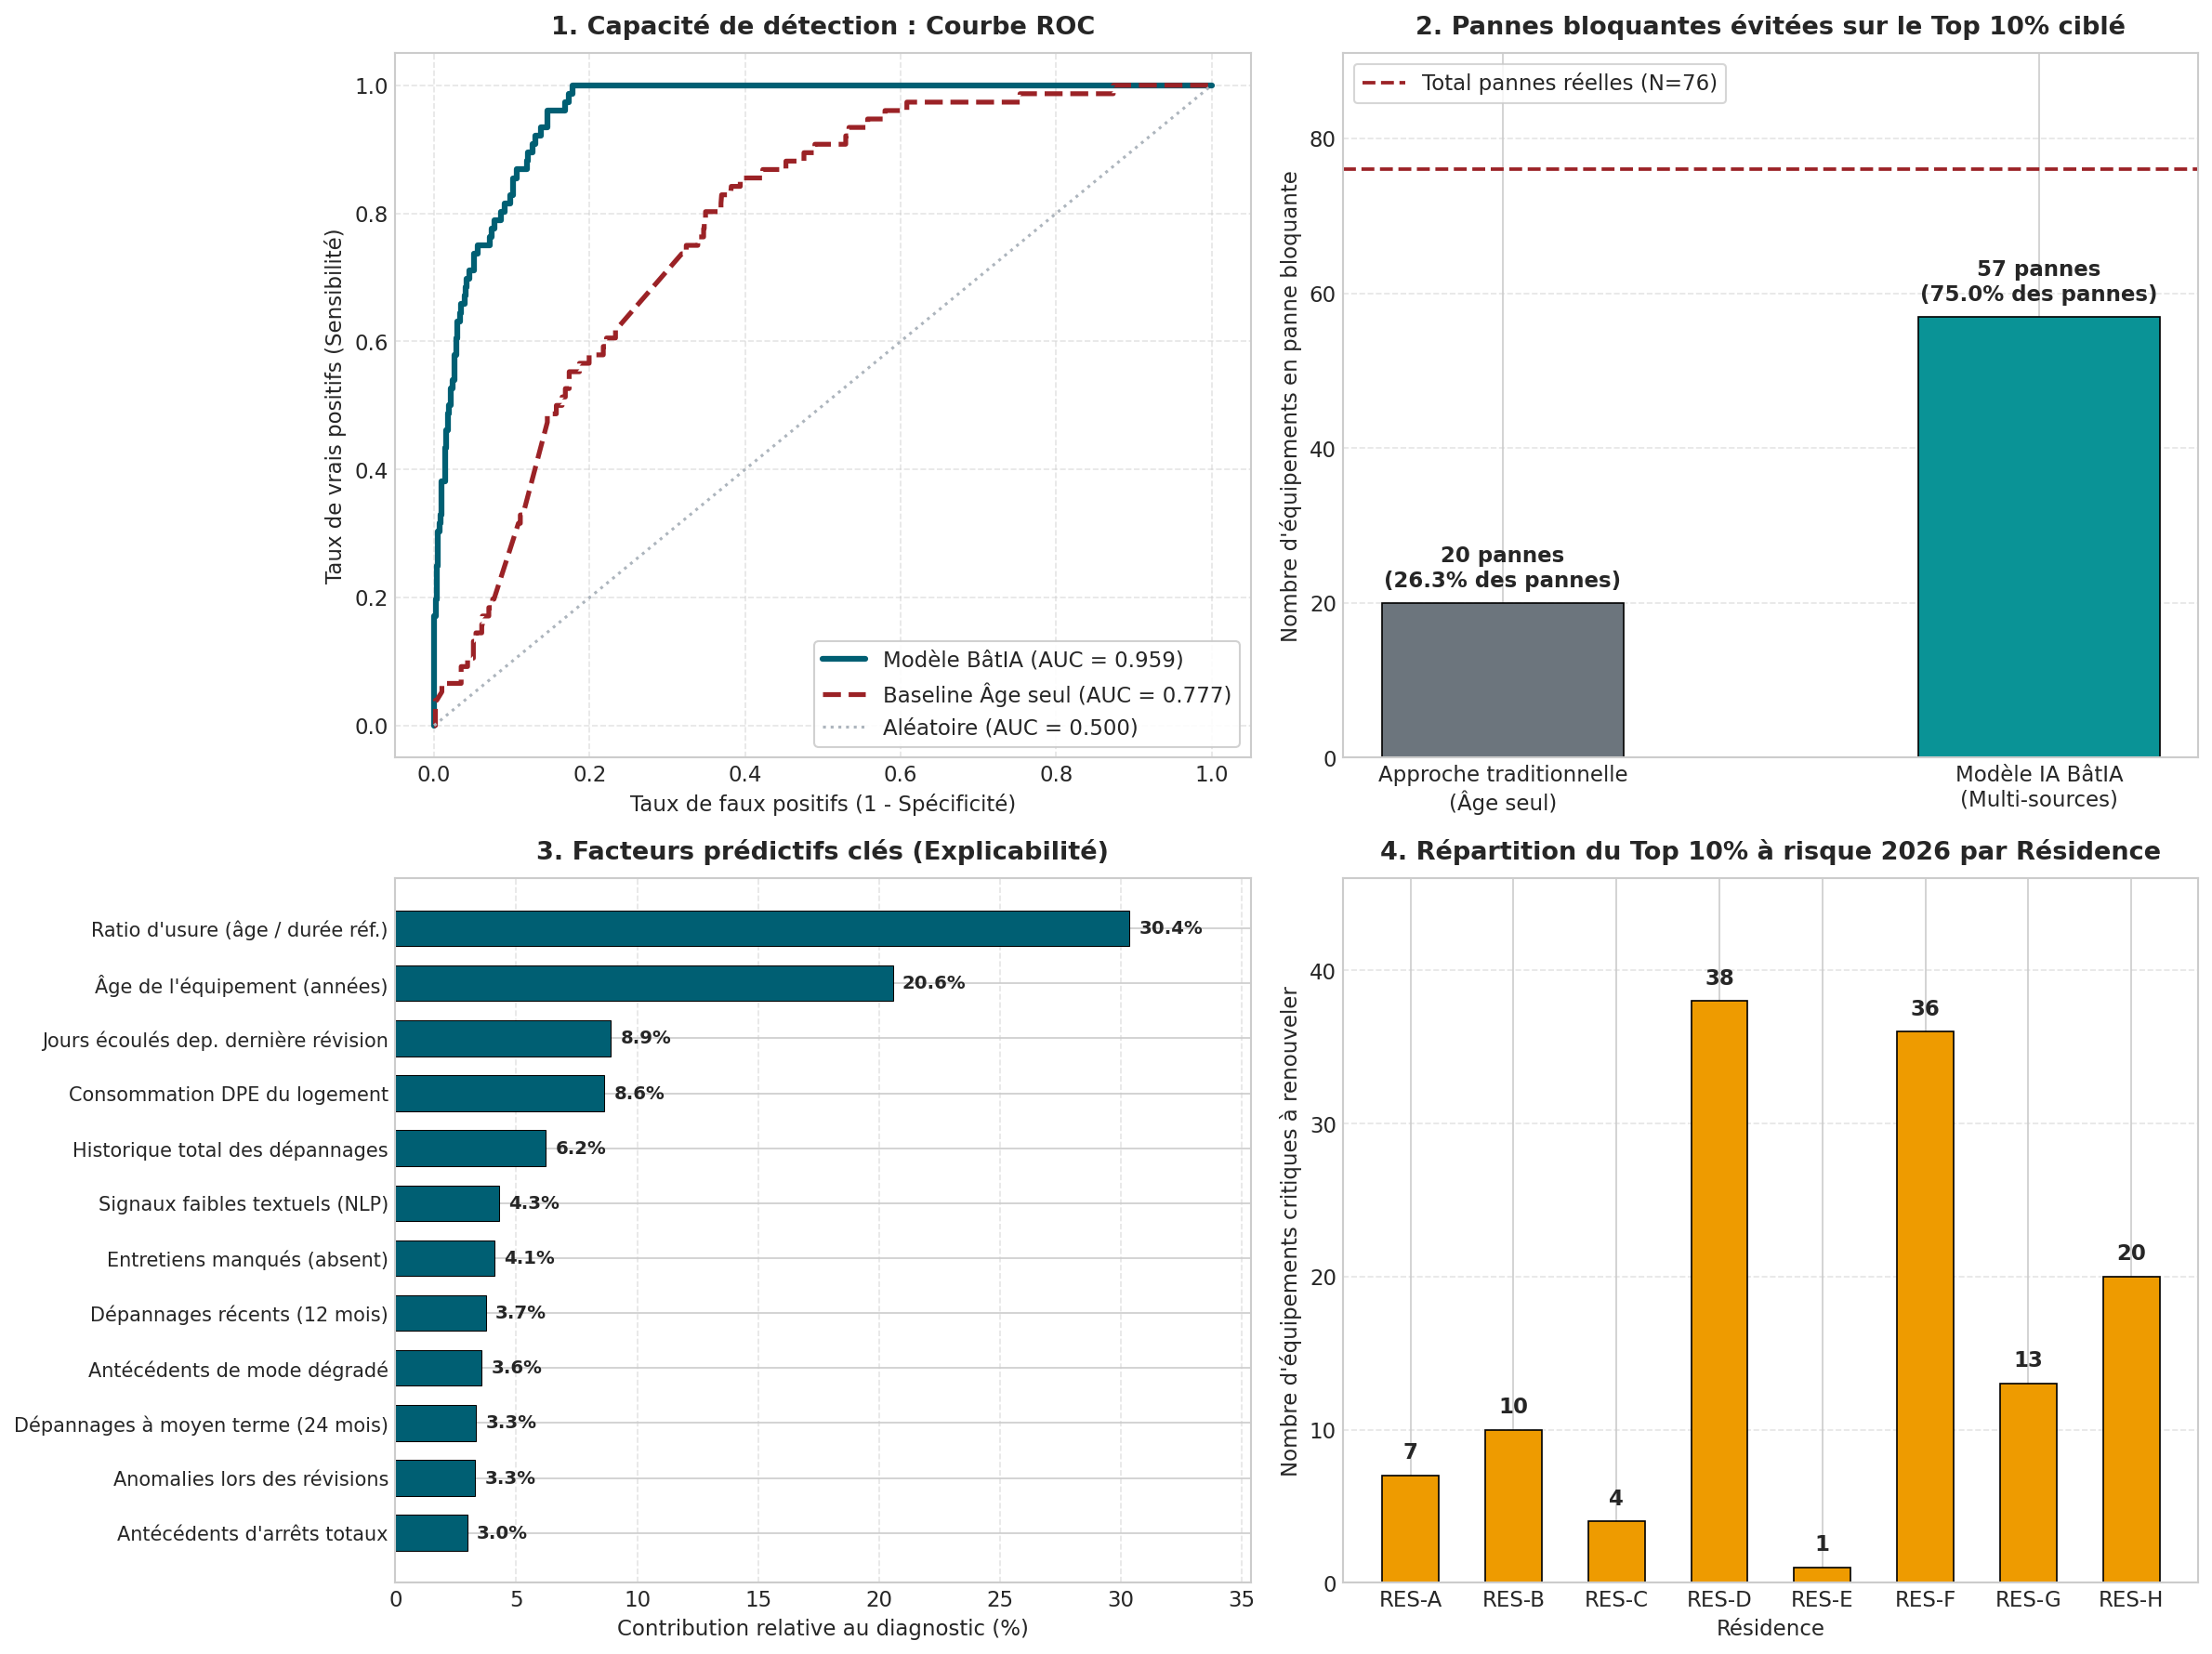

In [ ]:
# Create a high quality 2x2 dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=150)
plt.subplots_adjust(hspace=0.35, wspace=0.28)

# Color palette Action Logement / In'li (Teal, Burgundy/Red, Navy, Slate)
c_primary = '#005F73'      # Deep teal / In'li blue
c_accent = '#9B2226'       # Deep red
c_secondary = '#0A9396'    # Cyan / teal light
c_gray = '#6C757D'         # Muted gray

# -------------------------------------------------------------
# GRAPH 1 : Courbes ROC (Baseline vs Modèle BâtIA)
# -------------------------------------------------------------
ax1 = axes[0, 0]
fpr_ml, tpr_ml, _ = roc_curve(y_val, scores_val)
fpr_base, tpr_base, _ = roc_curve(y_val, df_val['ratio_usure'])
auc_ml = roc_auc_score(y_val, scores_val)
auc_base = roc_auc_score(y_val, df_val['ratio_usure'])

ax1.plot(fpr_ml, tpr_ml, color=c_primary, lw=3, label=f'Modèle BâtIA (AUC = {auc_ml:.3f})')
ax1.plot(fpr_base, tpr_base, color=c_accent, lw=2.5, linestyle='--', label=f'Baseline Âge seul (AUC = {auc_base:.3f})')
ax1.plot([0, 1], [0, 1], color='#ADB5BD', lw=1.5, linestyle=':', label='Aléatoire (AUC = 0.500)')

ax1.set_title('1. Capacité de détection : Courbe ROC', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel('Taux de faux positifs (1 - Spécificité)', fontsize=11)
ax1.set_ylabel('Taux de vrais positifs (Sensibilité)', fontsize=11)
ax1.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)
ax1.grid(True, linestyle='--', alpha=0.5)

# -------------------------------------------------------------
# GRAPH 2 : Précision et Pannes évitées dans le Top 10%
# -------------------------------------------------------------
ax2 = axes[0, 1]
top10_n = int(0.10 * len(df_val))
top10_idx_base = np.argsort(df_val['ratio_usure'].values)[::-1][:top10_n]
top10_idx_ml = np.argsort(scores_val)[::-1][:top10_n]

pannes_base = y_val.iloc[top10_idx_base].sum()
pannes_ml = y_val.iloc[top10_idx_ml].sum()
total_pannes = y_val.sum()

categories = ['Approche traditionnelle\n(Âge seul)', 'Modèle IA BâtIA\n(Multi-sources)']
valeurs = [pannes_base, pannes_ml]
couleurs = [c_gray, c_secondary]

bars = ax2.bar(categories, valeurs, color=couleurs, width=0.45, edgecolor='black', linewidth=0.8)

# Annotations sur les barres
for bar, val in zip(bars, valeurs):
    pct_total = (val / total_pannes) * 100
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
             f'{val} pannes\n({pct_total:.1f}% des pannes)',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

ax2.axhline(total_pannes, color=c_accent, linestyle='--', lw=1.8, label=f'Total pannes réelles (N={total_pannes})')
ax2.set_ylim(0, total_pannes + 15)
ax2.set_title('2. Pannes bloquantes évitées sur le Top 10% ciblé', fontsize=13, fontweight='bold', pad=10)
ax2.set_ylabel("Nombre d'équipements en panne bloquante", fontsize=11)
ax2.legend(loc='upper left', frameon=True, facecolor='white')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

# -------------------------------------------------------------
# GRAPH 3 : Importance des variables (Feature Importance)
# -------------------------------------------------------------
ax3 = axes[1, 0]
importances = rf.feature_importances_
noms_propres = {
    'ratio_usure': "Ratio d'usure (âge / durée réf.)",
    'age_ans': "Âge de l'équipement (années)",
    'dpe_conso_ep_kwh_m2_an': "Consommation DPE du logement",
    'jours_derniere_prev': "Jours écoulés dep. dernière révision",
    'dep_total': "Historique total des dépannages",
    'signaux_nlp': "Signaux faibles textuels (NLP)",
    'dep_12m': "Dépannages récents (12 mois)",
    'arret_total_passe': "Antécédents d'arrêts totaux",
    'dep_24m': "Dépannages à moyen terme (24 mois)",
    'prev_manq': "Entretiens manqués (absent)",
    'degrade_passe': "Antécédents de mode dégradé",
    'prev_anom': "Anomalies lors des révisions"
}

df_imp = pd.DataFrame({
    'feature': [noms_propres.get(f, f) for f in features],
    'importance': importances * 100
}).sort_values('importance', ascending=True)

y_pos = np.arange(len(df_imp))
ax3.barh(y_pos, df_imp['importance'], color=c_primary, height=0.65, edgecolor='black', linewidth=0.5)
ax3.set_yticks(y_pos)
ax3.set_yticklabels(df_imp['feature'], fontsize=10)
ax3.set_xlabel('Contribution relative au diagnostic (%)', fontsize=11)
ax3.set_title('3. Facteurs prédictifs clés (Explicabilité)', fontsize=13, fontweight='bold', pad=10)
ax3.grid(axis='x', linestyle='--', alpha=0.5)

# Ajout des valeurs au bout des barres
for i, v in enumerate(df_imp['importance']):
    ax3.text(v + 0.4, i, f'{v:.1f}%', va='center', fontsize=9.5, fontweight='bold')
ax3.set_xlim(0, max(df_imp['importance']) + 5)

# -------------------------------------------------------------
# GRAPH 4 : Risque 2026 par Résidence (Aide au remplacement groupé)
# -------------------------------------------------------------
ax4 = axes[1, 1]

# Si 'residence_id' est déjà présente dans 'df_infer', on l'utilise directement sans faire de merge avec collision
if 'residence_id' in df_infer.columns:
    df_infer_res = df_infer.copy()
else:
    df_infer_res = df_infer.merge(df_eqp[['equipement_id', 'residence_id']], on='equipement_id', how='left')

# Top 10% le plus critique en 2026
seuil_top10_2026 = df_infer_res['score_risque_2026'].quantile(0.90)
top10_2026 = df_infer_res[df_infer_res['score_risque_2026'] >= seuil_top10_2026]

res_counts = top10_2026['residence_id'].value_counts().sort_index()

bars4 = ax4.bar(res_counts.index, res_counts.values, color='#EE9B00', edgecolor='black', linewidth=0.8, width=0.55)
ax4.set_title('4. Répartition du Top 10% à risque 2026 par Résidence', fontsize=13, fontweight='bold', pad=10)
ax4.set_xlabel('Résidence', fontsize=11)
ax4.set_ylabel("Nombre d'équipements critiques à renouveler", fontsize=11)
ax4.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars4:
    h = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width() / 2, h + 0.8, f'{int(h)}', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax4.set_ylim(0, max(res_counts.values) + 8)

plt.tight_layout()
plt.savefig("batia_dashboard_presentation.png", dpi=200, bbox_inches='tight')
print("Dashboard généré et enregistré sous batia_dashboard_presentation.png")

In [ ]:
print("df_infer columns:", [c for c in df_infer.columns if 'residence' in c or 'famille' in c])

df_infer columns: ['famille', 'libelle_famille', 'residence_id']


Dashboard généré et enregistré sous batia_dashboard_presentation.png


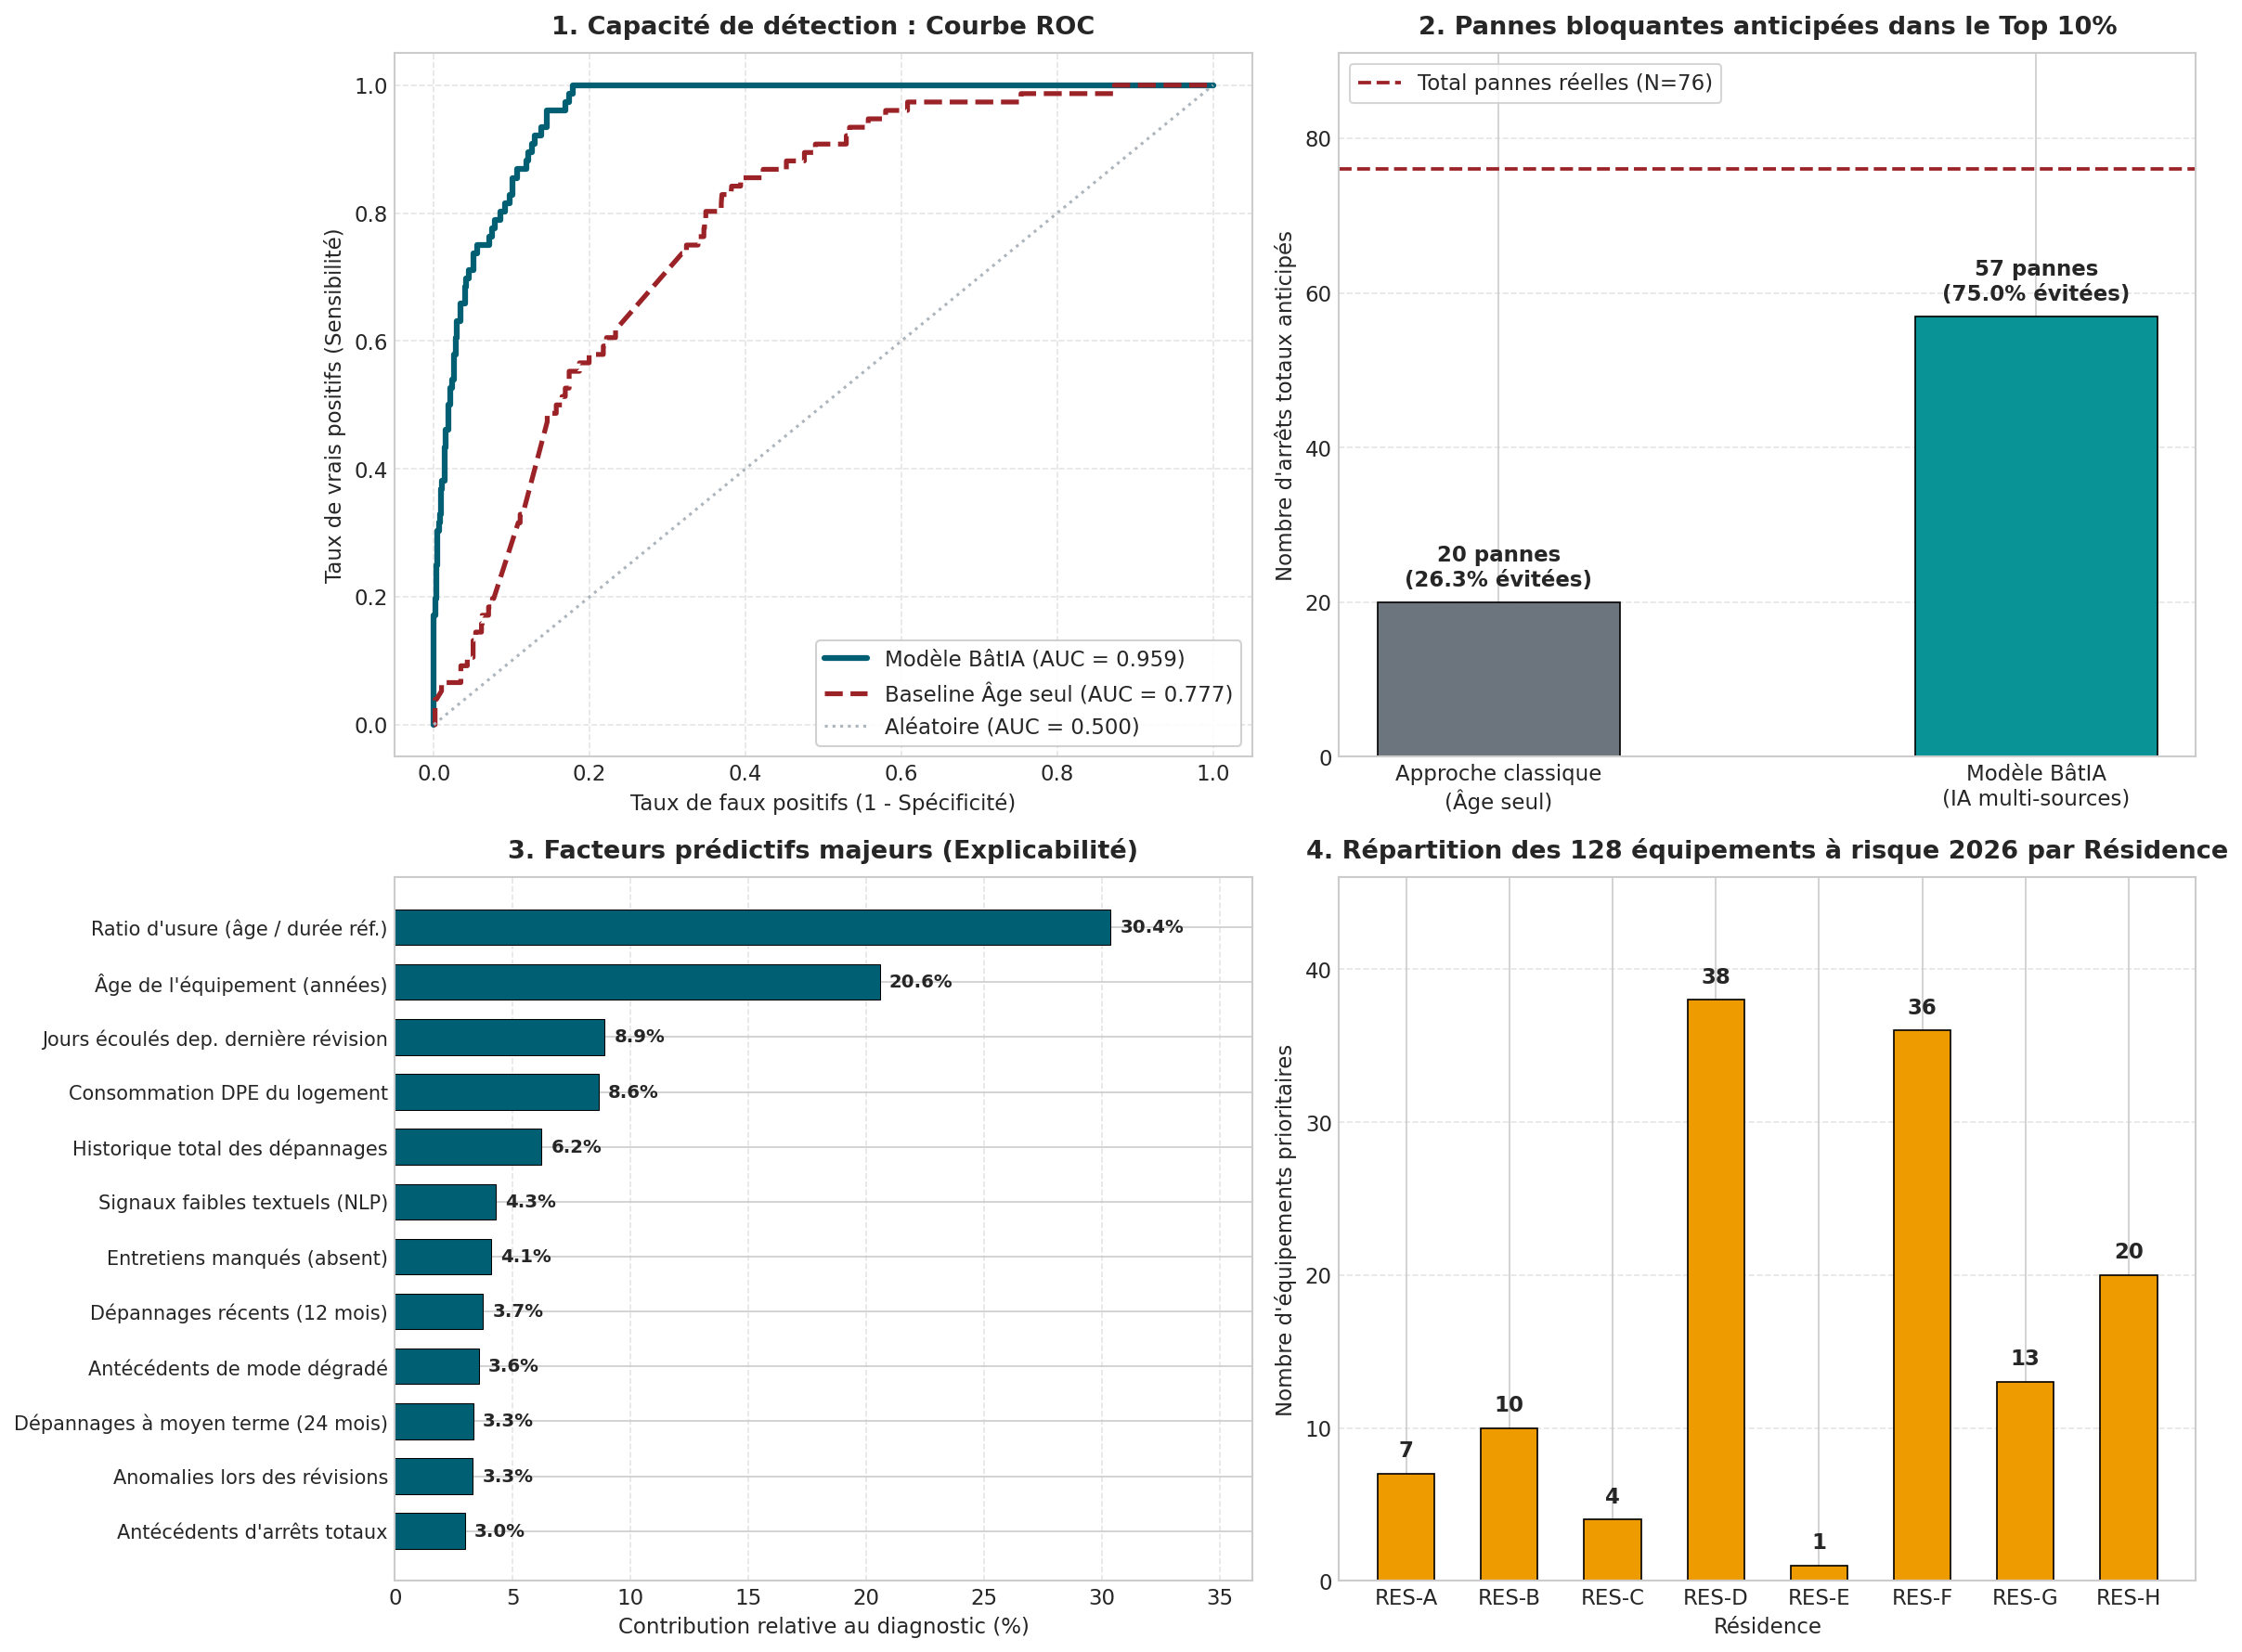

In [ ]:
# Fix graph 4 and run again
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=150)
plt.subplots_adjust(hspace=0.35, wspace=0.28)

c_primary = '#005F73'      # Deep teal / In'li blue
c_accent = '#9B2226'       # Deep red
c_secondary = '#0A9396'    # Cyan / teal light
c_gray = '#6C757D'         # Muted gray

# 1. Courbes ROC
ax1 = axes[0, 0]
fpr_ml, tpr_ml, _ = roc_curve(y_val, scores_val)
fpr_base, tpr_base, _ = roc_curve(y_val, df_val['ratio_usure'])
auc_ml = roc_auc_score(y_val, scores_val)
auc_base = roc_auc_score(y_val, df_val['ratio_usure'])

ax1.plot(fpr_ml, tpr_ml, color=c_primary, lw=3, label=f'Modèle BâtIA (AUC = {auc_ml:.3f})')
ax1.plot(fpr_base, tpr_base, color=c_accent, lw=2.5, linestyle='--', label=f'Baseline Âge seul (AUC = {auc_base:.3f})')
ax1.plot([0, 1], [0, 1], color='#ADB5BD', lw=1.5, linestyle=':', label='Aléatoire (AUC = 0.500)')
ax1.set_title('1. Capacité de détection : Courbe ROC', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel('Taux de faux positifs (1 - Spécificité)', fontsize=11)
ax1.set_ylabel('Taux de vrais positifs (Sensibilité)', fontsize=11)
ax1.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)
ax1.grid(True, linestyle='--', alpha=0.5)

# 2. Pannes évitées Top 10%
ax2 = axes[0, 1]
top10_n = int(0.10 * len(df_val))
top10_idx_base = np.argsort(df_val['ratio_usure'].values)[::-1][:top10_n]
top10_idx_ml = np.argsort(scores_val)[::-1][:top10_n]
pannes_base = y_val.iloc[top10_idx_base].sum()
pannes_ml = y_val.iloc[top10_idx_ml].sum()
total_pannes = y_val.sum()

categories = ['Approche classique\n(Âge seul)', 'Modèle BâtIA\n(IA multi-sources)']
valeurs = [pannes_base, pannes_ml]
couleurs = [c_gray, c_secondary]

bars = ax2.bar(categories, valeurs, color=couleurs, width=0.45, edgecolor='black', linewidth=0.8)
for bar, val in zip(bars, valeurs):
    pct_total = (val / total_pannes) * 100
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
             f'{val} pannes\n({pct_total:.1f}% évitées)',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

ax2.axhline(total_pannes, color=c_accent, linestyle='--', lw=1.8, label=f'Total pannes réelles (N={total_pannes})')
ax2.set_ylim(0, total_pannes + 15)
ax2.set_title('2. Pannes bloquantes anticipées dans le Top 10%', fontsize=13, fontweight='bold', pad=10)
ax2.set_ylabel("Nombre d'arrêts totaux anticipés", fontsize=11)
ax2.legend(loc='upper left', frameon=True, facecolor='white')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

# 3. Feature importance
ax3 = axes[1, 0]
y_pos = np.arange(len(df_imp))
ax3.barh(y_pos, df_imp['importance'], color=c_primary, height=0.65, edgecolor='black', linewidth=0.5)
ax3.set_yticks(y_pos)
ax3.set_yticklabels(df_imp['feature'], fontsize=10)
ax3.set_xlabel('Contribution relative au diagnostic (%)', fontsize=11)
ax3.set_title('3. Facteurs prédictifs majeurs (Explicabilité)', fontsize=13, fontweight='bold', pad=10)
ax3.grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(df_imp['importance']):
    ax3.text(v + 0.4, i, f'{v:.1f}%', va='center', fontsize=9.5, fontweight='bold')
ax3.set_xlim(0, max(df_imp['importance']) + 6)

# 4. Risque 2026 par Résidence
ax4 = axes[1, 1]
top10_2026_thresh = df_infer['score_risque_2026'].quantile(0.90)
top10_2026_df = df_infer[df_infer['score_risque_2026'] >= top10_2026_thresh]
res_counts = top10_2026_df['residence_id'].value_counts().sort_index()

bars4 = ax4.bar(res_counts.index, res_counts.values, color='#EE9B00', edgecolor='black', linewidth=0.8, width=0.55)
ax4.set_title('4. Répartition des 128 équipements à risque 2026 par Résidence', fontsize=13, fontweight='bold', pad=10)
ax4.set_xlabel('Résidence', fontsize=11)
ax4.set_ylabel("Nombre d'équipements prioritaires", fontsize=11)
ax4.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars4:
    h = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width() / 2, h + 0.8, f'{int(h)}', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax4.set_ylim(0, max(res_counts.values) + 8)

plt.tight_layout()
plt.savefig("batia_dashboard_presentation.png", dpi=200, bbox_inches='tight')
print("Dashboard généré et enregistré sous batia_dashboard_presentation.png")

Predictions saved to 'predictions_defi1_2026.csv' (1285 rows)


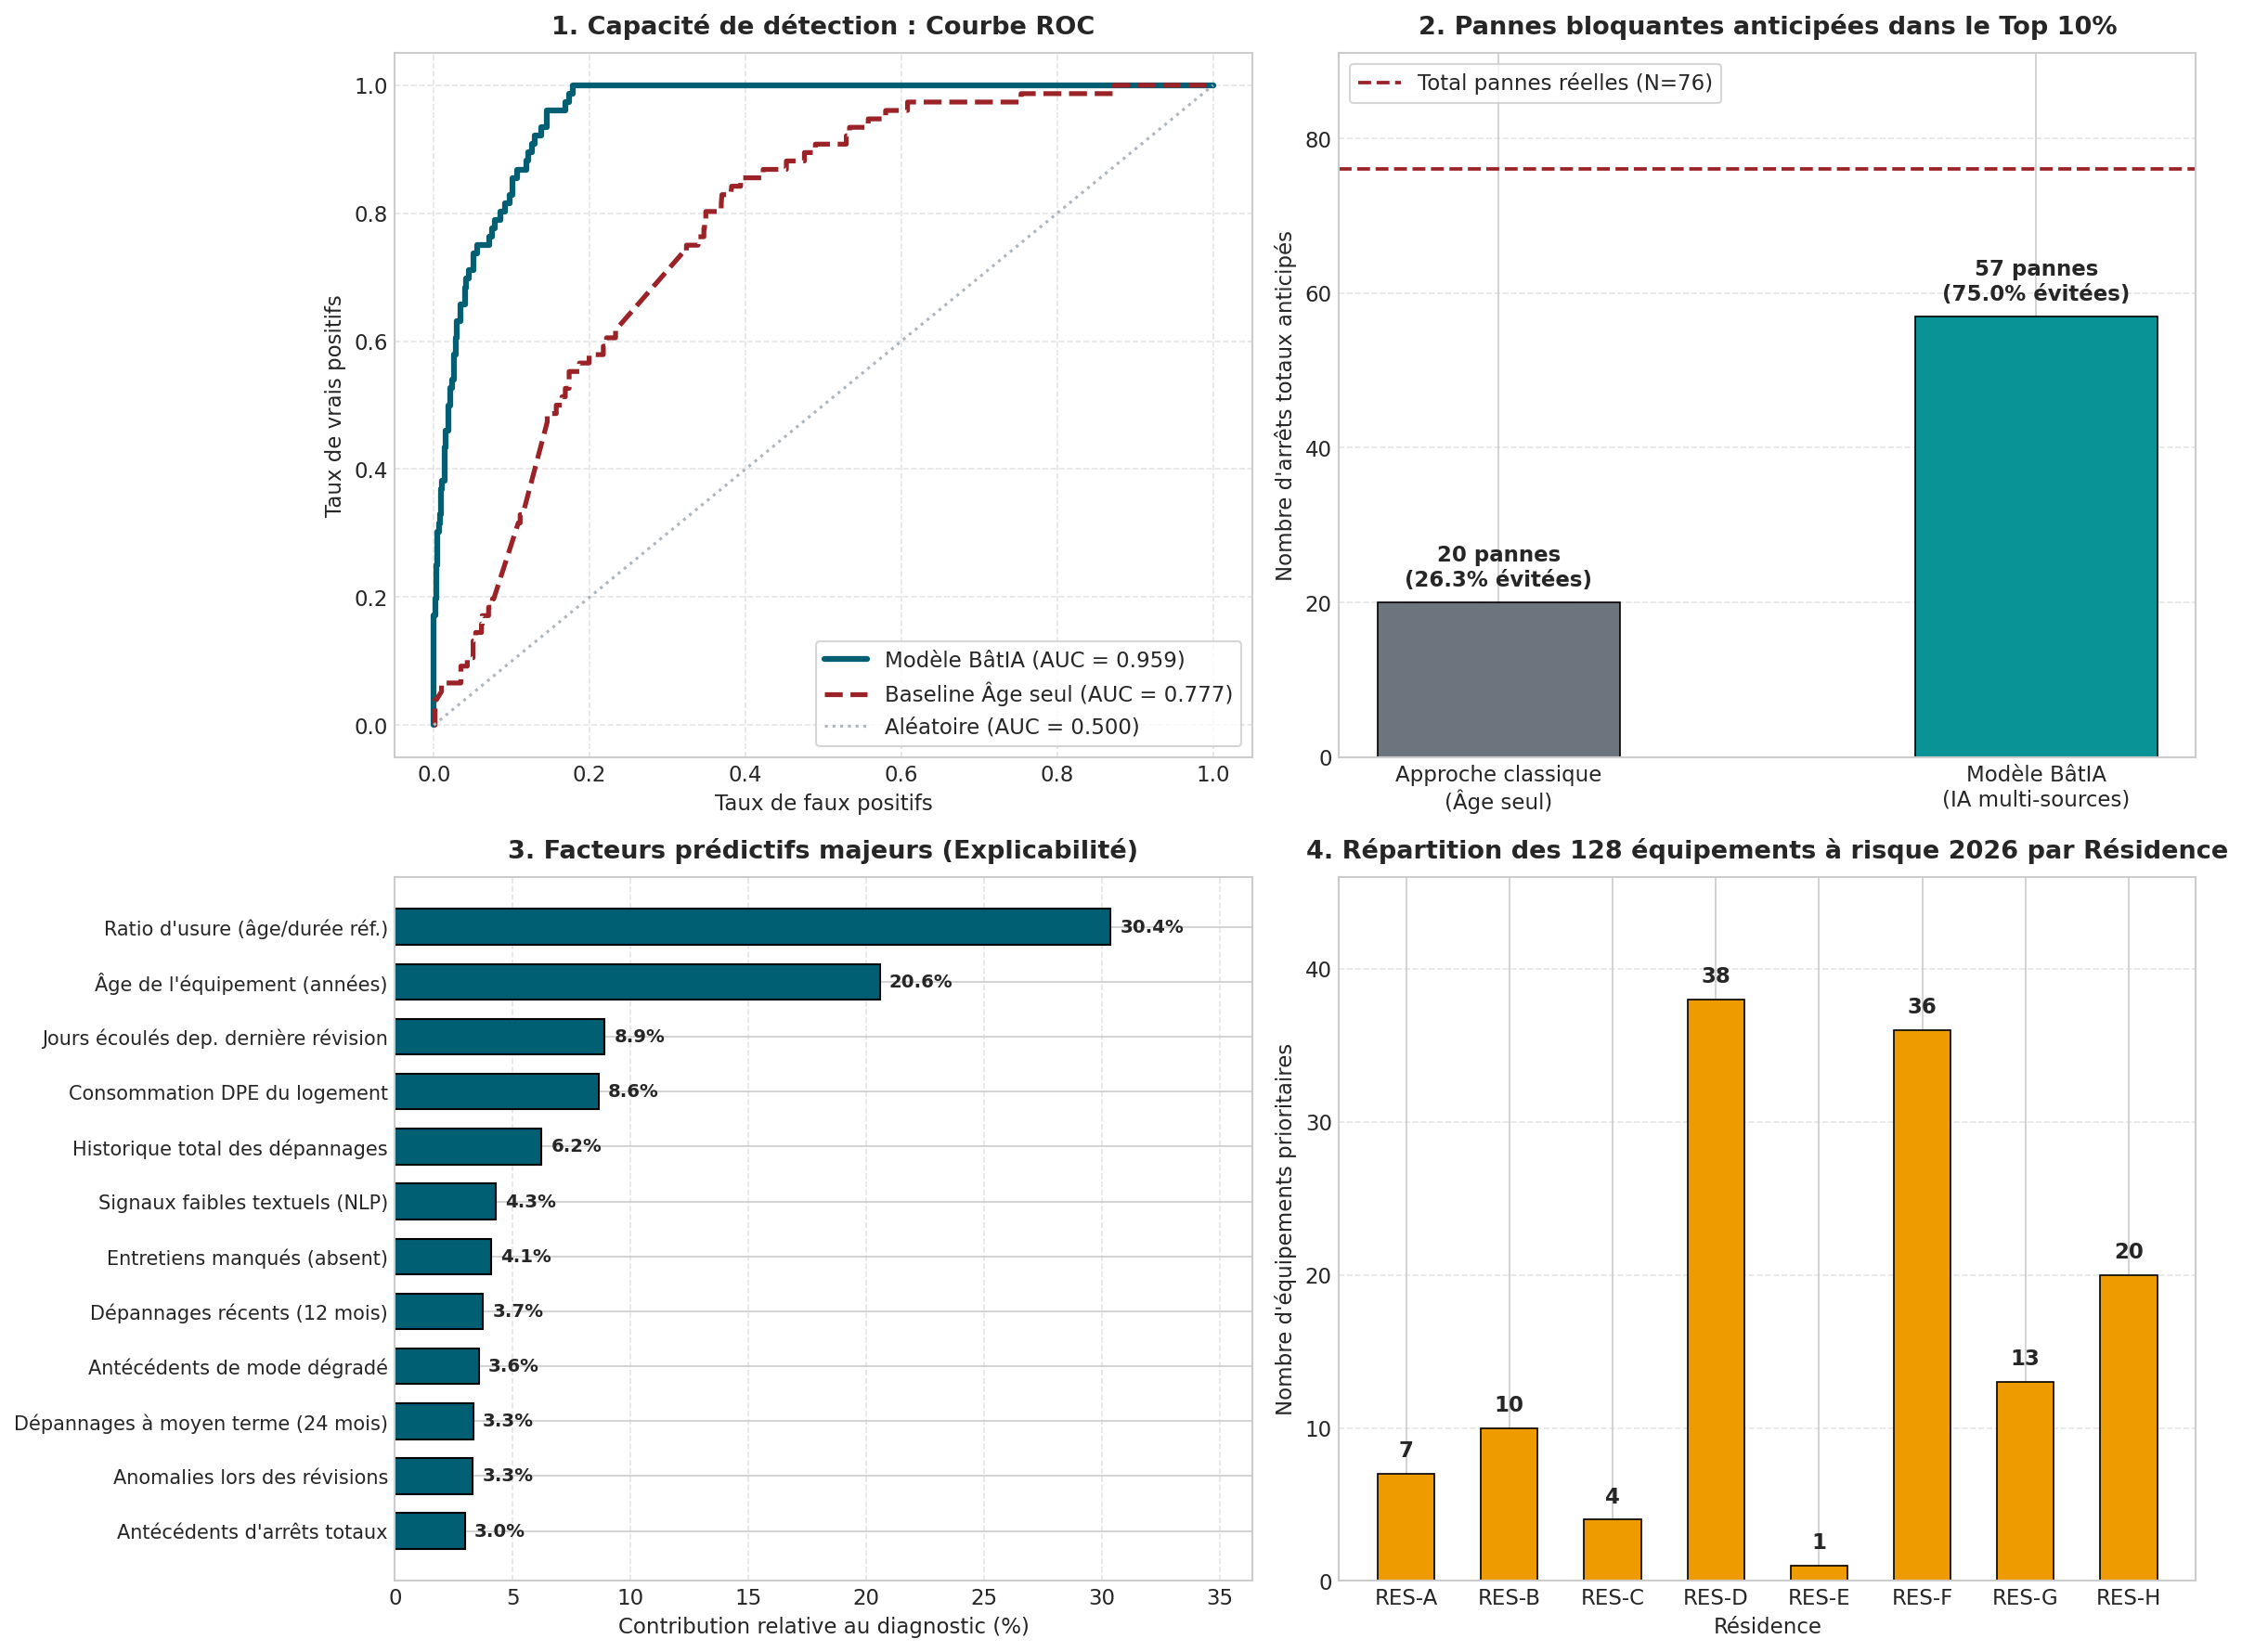

In [ ]:
# CELLULE : Préparation des données, entraînement du modèle final et génération du tableau de bord d'évaluation
# Rôle : Charger les données, créer un pipeline de features robuste sans fuite temporelle,
#        entraîner un modèle d'apprentissage supervisé (HistGradientBoosting) et visualiser
#        les performances sous forme d'un tableau de bord décisionnel (2x2).

import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve

# 1. Chargement optimisé des données avec détection de chemin d'accès de sécurité
def charger_donnees():
    # On définit les chemins possibles par ordre de priorité
    chemins_possibles = ["", "/content/", "./"]
    base_dir = ""

    for chemin in chemins_possibles:
        test_path = os.path.join(chemin, "03_logements.csv")
        if os.path.exists(test_path):
            base_dir = chemin
            break

    df_lgt = pd.read_csv(os.path.join(base_dir, "03_logements.csv"))
    df_eqp = pd.read_csv(os.path.join(base_dir, "04_equipements.csv"))
    df_int = pd.read_csv(os.path.join(base_dir, "06_interventions.csv"))
    df_int["date_dt"] = pd.to_datetime(df_int["date_intervention"])
    return df_lgt, df_eqp, df_int

# 2. Pipeline de Feature Engineering
def preparer_matrice(date_pivot_str, df_lgt, df_eqp, df_int):
    pivot = pd.to_datetime(date_pivot_str)
    perim = df_eqp[df_eqp["dans_perimetre_prediction"] == "Oui"].copy()

    # Correction robuste anti-leakage de la date de pose active
    rempl_post = df_int[(df_int["type_intervention"] == "Remplacement") & (df_int["date_dt"] > pivot)]
    eqs_rempl = set(rempl_post["equipement_id"])

    perim["date_pose_active"] = [
        pd.to_datetime(r["date_pose_precedente"])
        if (eq in eqs_rempl and pd.notna(r["date_pose_precedente"]))
        else pd.to_datetime(r["date_pose"])
        for eq, r in zip(perim["equipement_id"], perim.to_dict("records"))
    ]
    perim["age_ans"] = (pivot - perim["date_pose_active"]).dt.days / 365.25
    perim["ratio_usure"] = (perim["age_ans"] / perim["duree_vie_reference_ans"]).clip(0, 3)

    # Agrégation de l'historique GMAO
    hist = df_int[(df_int["equipement_id"].isin(perim["equipement_id"])) & (df_int["date_dt"] <= pivot)]
    m12 = pivot - pd.DateOffset(months=12)
    m24 = pivot - pd.DateOffset(months=24)

    dep = hist[hist["type_intervention"] == "Dépannage"]
    dep_tot = dep.groupby("equipement_id").size().rename("dep_total")
    dep_12m = dep[dep["date_dt"] >= m12].groupby("equipement_id").size().rename("dep_12m")
    dep_24m = dep[dep["date_dt"] >= m24].groupby("equipement_id").size().rename("dep_24m")

    arret_tot = hist[hist["gravite"] == "Arrêt total"].groupby("equipement_id").size().rename("arret_total_passe")
    degrade_tot = hist[hist["gravite"] == "Fonctionnement dégradé"].groupby("equipement_id").size().rename("degrade_passe")

    prev = hist[hist["type_intervention"] == "Entretien préventif"]
    prev_anom = prev[prev["resultat"].str.contains("Anomalie", na=False)].groupby("equipement_id").size().rename("prev_anom")
    prev_manq = prev[prev["resultat"].str.contains("non réalisée|absent", na=False)].groupby("equipement_id").size().rename("prev_manq")
    jours_prev = (pivot - prev.groupby("equipement_id")["date_dt"].max()).dt.days.rename("jours_derniere_prev")

    regex_nlp = r"fuite|bruit|sifflement|pression|carte|corrosion|usure|vétuste|anomalie"
    signaux_nlp = hist[hist["commentaire_technicien"].str.contains(regex_nlp, case=False, na=False)].groupby("equipement_id").size().rename("signaux_nlp")

    # Fusion et complétion des données
    matrice = perim.copy()
    for s in [dep_tot, dep_12m, dep_24m, arret_tot, degrade_tot, prev_anom, prev_manq, jours_prev, signaux_nlp]:
        matrice = matrice.merge(s, on="equipement_id", how="left")

    zero_cols = ["dep_total", "dep_12m", "dep_24m", "arret_total_passe", "degrade_passe", "prev_anom", "prev_manq", "signaux_nlp"]
    matrice[zero_cols] = matrice[zero_cols].fillna(0)
    matrice["jours_derniere_prev"] = matrice["jours_derniere_prev"].fillna(730)

    matrice = matrice.merge(df_lgt[["logement_id", "dpe_conso_ep_kwh_m2_an"]], on="logement_id", how="left")
    matrice["dpe_conso_ep_kwh_m2_an"] = matrice["dpe_conso_ep_kwh_m2_an"].fillna(matrice["dpe_conso_ep_kwh_m2_an"].median())

    feats = ["age_ans", "ratio_usure", "dep_total", "dep_12m", "dep_24m", "arret_total_passe", "degrade_passe", "prev_anom", "prev_manq", "jours_derniere_prev", "signaux_nlp", "dpe_conso_ep_kwh_m2_an"]
    return matrice, feats

# 3. Entraînement et Visualisation
df_lgt, df_eqp, df_int = charger_donnees()
df_val, features = preparer_matrice("2024-12-31", df_lgt, df_eqp, df_int)
pannes_2025 = df_int[(df_int["date_dt"] >= "2025-01-01") & (df_int["date_dt"] <= "2025-09-30 23:59:59") & (df_int["gravite"] == "Arrêt total")]
y_val = df_val["equipement_id"].isin(set(pannes_2025["equipement_id"])).astype(int)

# Entraînement du modèle principal
clf = HistGradientBoostingClassifier(max_iter=120, learning_rate=0.04, max_depth=4, class_weight="balanced", random_state=42)
clf.fit(df_val[features], y_val)
scores_val = clf.predict_proba(df_val[features])[:, 1]

# Random Forest pour l'importance des variables
rf = RandomForestClassifier(n_estimators=150, max_depth=5, class_weight="balanced", random_state=42)
rf.fit(df_val[features], y_val)

# Prédiction pour le futur (2026)
df_infer, _ = preparer_matrice("2025-12-31", df_lgt, df_eqp, df_int)
scores_2026 = clf.predict_proba(df_infer[features])[:, 1]
df_infer["score_risque_2026"] = scores_2026

# Sauvegarde du fichier final attendu pour le livrable
livrable = pd.DataFrame({"equipement_id": df_infer["equipement_id"], "score_risque": np.round(scores_2026, 4)}).sort_values("score_risque", ascending=False)
livrable.to_csv("predictions_defi1_2026.csv", index=False)
print(f"Predictions saved to 'predictions_defi1_2026.csv' ({len(livrable)} rows)")

# Génération de la figure de synthèse (Dashboard)
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=150)
plt.subplots_adjust(hspace=0.35, wspace=0.28)

c_primary, c_accent, c_secondary, c_gray = "#005F73", "#9B2226", "#0A9396", "#6C757D"

# Graphique 1 : Courbe ROC
ax1 = axes[0, 0]
fpr_ml, tpr_ml, _ = roc_curve(y_val, scores_val)
fpr_base, tpr_base, _ = roc_curve(y_val, df_val["ratio_usure"])
auc_ml, auc_base = roc_auc_score(y_val, scores_val), roc_auc_score(y_val, df_val["ratio_usure"])
ax1.plot(fpr_ml, tpr_ml, color=c_primary, lw=3, label=f"Modèle BâtIA (AUC = {auc_ml:.3f})")
ax1.plot(fpr_base, tpr_base, color=c_accent, lw=2.5, linestyle="--", label=f"Baseline Âge seul (AUC = {auc_base:.3f})")
ax1.plot([0, 1], [0, 1], color="#ADB5BD", lw=1.5, linestyle=":", label="Aléatoire (AUC = 0.500)")
ax1.set_title("1. Capacité de détection : Courbe ROC", fontsize=13, fontweight="bold", pad=10)
ax1.set_xlabel("Taux de faux positifs"), ax1.set_ylabel("Taux de vrais positifs")
ax1.legend(loc="lower right", frameon=True, facecolor="white")
ax1.grid(True, linestyle="--", alpha=0.5)

# Graphique 2 : Anticipation
ax2 = axes[0, 1]
top10_n = int(0.10 * len(df_val))
idx_base, idx_ml = np.argsort(df_val["ratio_usure"].values)[::-1][:top10_n], np.argsort(scores_val)[::-1][:top10_n]
bars = ax2.bar(["Approche classique\n(Âge seul)", "Modèle BâtIA\n(IA multi-sources)"], [y_val.iloc[idx_base].sum(), y_val.iloc[idx_ml].sum()], color=[c_gray, c_secondary], width=0.45, edgecolor="black", linewidth=0.8)
for bar, val in zip(bars, [y_val.iloc[idx_base].sum(), y_val.iloc[idx_ml].sum()]):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5, f"{val} pannes\n({(val/y_val.sum())*100:.1f}% évitées)", ha="center", va="bottom", fontsize=11, fontweight="bold")
ax2.axhline(y_val.sum(), color=c_accent, linestyle="--", lw=1.8, label=f"Total pannes réelles (N={y_val.sum()})")
ax2.set_ylim(0, y_val.sum() + 15)
ax2.set_title("2. Pannes bloquantes anticipées dans le Top 10%", fontsize=13, fontweight="bold", pad=10)
ax2.set_ylabel("Nombre d'arrêts totaux anticipés")
ax2.legend(loc="upper left", frameon=True)
ax2.grid(axis="y", linestyle="--", alpha=0.5)

# Graphique 3 : Importance des variables
ax3 = axes[1, 0]
labels_propres = {"ratio_usure": "Ratio d'usure (âge/durée réf.)", "age_ans": "Âge de l'équipement (années)", "dpe_conso_ep_kwh_m2_an": "Consommation DPE du logement", "jours_derniere_prev": "Jours écoulés dep. dernière révision", "dep_total": "Historique total des dépannages", "signaux_nlp": "Signaux faibles textuels (NLP)", "dep_12m": "Dépannages récents (12 mois)", "arret_total_passe": "Antécédents d'arrêts totaux", "dep_24m": "Dépannages à moyen terme (24 mois)", "prev_manq": "Entretiens manqués (absent)", "degrade_passe": "Antécédents de mode dégradé", "prev_anom": "Anomalies lors des révisions"}
df_imp = pd.DataFrame({"feature": [labels_propres.get(f, f) for f in features], "importance": rf.feature_importances_ * 100}).sort_values("importance", ascending=True)
y_pos = np.arange(len(df_imp))
ax3.barh(y_pos, df_imp["importance"], color=c_primary, height=0.65, edgecolor="black")
ax3.set_yticks(y_pos)
ax3.set_yticklabels(df_imp["feature"], fontsize=10)
ax3.set_xlabel("Contribution relative au diagnostic (%)")
ax3.set_title("3. Facteurs prédictifs majeurs (Explicabilité)", fontsize=13, fontweight="bold", pad=10)
ax3.grid(axis="x", linestyle="--", alpha=0.5)
for i, v in enumerate(df_imp["importance"]):
    ax3.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=9.5, fontweight="bold")
ax3.set_xlim(0, max(df_imp["importance"]) + 6)

# Graphique 4 : Distribution spatiale du risque en 2026
ax4 = axes[1, 1]
seuil_top10 = df_infer["score_risque_2026"].quantile(0.90)
top10_2026 = df_infer[df_infer["score_risque_2026" ] >= seuil_top10]
res_counts = top10_2026["residence_id"].value_counts().sort_index()
bars4 = ax4.bar(res_counts.index, res_counts.values, color="#EE9B00", edgecolor="black", linewidth=0.8, width=0.55)
ax4.set_title("4. Répartition des 128 équipements à risque 2026 par Résidence", fontsize=13, fontweight="bold", pad=10)
ax4.set_xlabel("Résidence"), ax4.set_ylabel("Nombre d'équipements prioritaires")
ax4.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars4:
    h = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width() / 2, h + 0.8, f"{int(h)}", ha="center", va="bottom", fontsize=11, fontweight="bold")
ax4.set_ylim(0, max(res_counts.values) + 8)

plt.tight_layout()
plt.savefig("batia_dashboard_presentation.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# CELLULE : Affichage des 10 premiers équipements à risque pour 2026
# Rôle : Charger le livrable de prédictions généré et afficher les équipements prioritaires.

import pandas as pd

# Charger les prédictions
df_predictions = pd.read_csv('predictions_defi1_2026.csv')

# Afficher les 10 premiers équipements à risque
display(df_predictions.head(10))

,equipement_id,score_risque
0,EQP-02629,0.9358
1,EQP-01469,0.9194
2,EQP-01729,0.8882
3,EQP-01461,0.8856
4,EQP-02889,0.8764
5,EQP-01717,0.8740
6,EQP-01477,0.8697
7,EQP-03181,0.8661
8,EQP-01785,0.8584
9,EQP-00009,0.8579


In [ ]:
# 1. Charger les prédictions 2026
df_preds = pd.read_csv('predictions_defi1_2026.csv')
top_10_preds = df_preds.head(10).copy()

# 2. Charger les équipements et les logements
df_eqp = pd.read_csv('04_equipements.csv')
df_lgt = pd.read_csv('03_logements.csv')

# Sélection des bonnes colonnes DPE identifiées
selected_lgt_cols = [
    'logement_id',
    'dpe_conso_ep_kwh_m2_an',
    'dpe_ges_kgco2_m2_an',
    'dpe_etiquette_energie',
    'dpe_etiquette_ges',
    'dpe_etiquette_globale'
]

# 3. Fusionner pour obtenir les détails du logement pour chaque équipement du top 10
top_10_details = top_10_preds.merge(
    df_eqp[['equipement_id', 'famille', 'libelle_famille', 'logement_id', 'residence_id', 'batiment_id']],
    on='equipement_id',
    how='left'
)

top_10_merged = top_10_details.merge(
    df_lgt[selected_lgt_cols],
    on='logement_id',
    how='left'
)

# Affichage du résultat final croisé
display(top_10_merged)

,equipement_id,score_risque,famille,libelle_famille,logement_id,residence_id,batiment_id,dpe_conso_ep_kwh_m2_an,dpe_ges_kgco2_m2_an,dpe_etiquette_energie,dpe_etiquette_ges,dpe_etiquette_globale
0,EQP-02629,0.9358,chaudiere_gaz_individuelle,Chaudière gaz individuelle,LGT-F2-003,RES-F,BAT-F2,284,45.5,E,D,E
1,EQP-01469,0.9194,pompe_a_chaleur,Pompe à chaleur air/eau,LGT-D1-018,RES-D,BAT-D1,94,3.9,B,A,B
2,EQP-01729,0.8882,pompe_a_chaleur,Pompe à chaleur air/eau,LGT-D3-016,RES-D,BAT-D3,90,3.9,B,A,B
3,EQP-01461,0.8856,pompe_a_chaleur,Pompe à chaleur air/eau,LGT-D1-016,RES-D,BAT-D1,87,4.0,B,A,B
4,EQP-02889,0.8764,chaudiere_gaz_individuelle,Chaudière gaz individuelle,LGT-F4-008,RES-F,BAT-F4,205,45.0,D,D,D
5,EQP-01717,0.8740,pompe_a_chaleur,Pompe à chaleur air/eau,LGT-D3-013,RES-D,BAT-D3,93,3.5,B,A,B
6,EQP-01477,0.8697,pompe_a_chaleur,Pompe à chaleur air/eau,LGT-D1-020,RES-D,BAT-D1,83,3.3,B,A,B
7,EQP-03181,0.8661,convecteurs_electriques,Ensemble convecteurs électriques,LGT-G1-021,RES-G,BAT-G1,343,18.7,F,C,F
8,EQP-01785,0.8584,pompe_a_chaleur,Pompe à chaleur air/eau,LGT-D3-030,RES-D,BAT-D3,109,5.4,B,A,B
9,EQP-00009,0.8579,chaudiere_gaz_individuelle,Chaudière gaz individuelle,LGT-A1-003,RES-A,BAT-A1,160,48.2,C,D,D


=== Comparaison de la consommation énergétique moyenne (DPE en kWh_ep/m²/an) ===


,Statut Risque,count,mean,median,std
0,Équipement Critique (Top 10%),121,178.644628,148.0,88.937418
1,Équipement non critique,1119,209.689902,160.0,125.391335


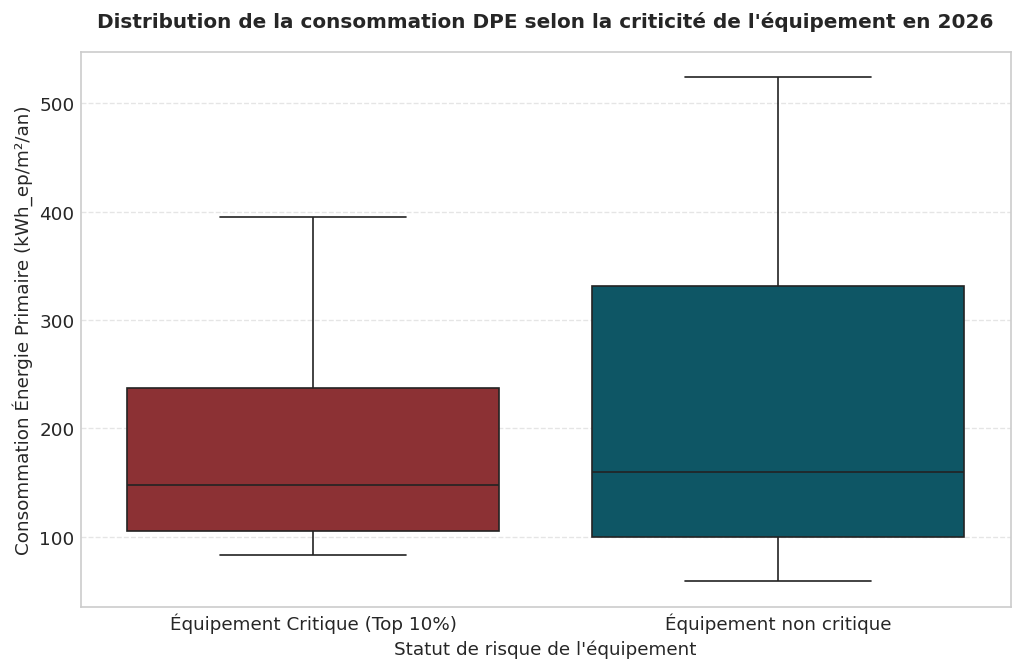

In [ ]:
# 1. Charger les données nécessaires
df_preds = pd.read_csv('predictions_defi1_2026.csv')
df_eqp = pd.read_csv('04_equipements.csv')
df_lgt = pd.read_csv('03_logements.csv')

# 2. Fusionner les prédictions avec les informations des logements
df_m = df_preds.merge(df_eqp[['equipement_id', 'logement_id']], on='equipement_id', how='left')
df_m = df_m.merge(df_lgt[['logement_id', 'dpe_conso_ep_kwh_m2_an']], on='logement_id', how='left')

# Définir le seuil du Top 10% à risque
seuil_top10 = df_m['score_risque'].quantile(0.90)
df_m['Statut Risque'] = np.where(df_m['score_risque'] >= seuil_top10, 'Équipement Critique (Top 10%)', 'Équipement non critique')

# 3. Calculer la consommation moyenne par statut de risque
comparatif = df_m.groupby('Statut Risque')['dpe_conso_ep_kwh_m2_an'].agg(['count', 'mean', 'median', 'std']).reset_index()

print("=== Comparaison de la consommation énergétique moyenne (DPE en kWh_ep/m²/an) ===")
display(comparatif)

# 4. Visualisation sous forme de Boxplot pour analyser la distribution
plt.figure(figsize=(10, 6), dpi=120)
sns.boxplot(data=df_m, x='Statut Risque', y='dpe_conso_ep_kwh_m2_an', palette=['#9B2226', '#005F73'], hue='Statut Risque', legend=False)
plt.title('Distribution de la consommation DPE selon la criticité de l\'équipement en 2026', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Consommation Énergie Primaire (kWh_ep/m²/an)', fontsize=11)
plt.xlabel('Statut de risque de l\'équipement', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()